# URB-04 · Modelos predictivos de IA · Versión complementaria (auditoría, noviembre 2026)

> **Copia complementaria** de `URB04_patrones_riesgo_urbano_piloto.ipynb`. **El notebook original no se modifica.**

**Objetivo de esta copia:** definir la variable objetivo y el horizonte, preparar características sin fuga de información, comparar tres algoritmos y documentar métricas y protocolo de evaluación, sin presentar resultados simulados como validación real.

| Parte | Contenido | ¿Se ejecuta para la entrega? |
|---|---|---|
| **Parte C** (a continuación) | Bloque nuevo y autocontenido que cubre los ajustes de la auditoría | **Sí.** Ejecutar desde la celda C.0 hasta el final de la Parte C |
| **Parte B** | Copia del notebook original con ajustes puntuales marcados `# [AJUSTE AUDITORÍA]` | No es necesaria (referencia) |

**Cómo ejecutar:** ver `README_COMPLEMENTARIO.md` en la carpeta del proyecto. En Colab, poner `CLONAR_REPO = True` en la celda C.0 para que los datos de prueba y `COMUN/` se descarguen del repositorio.
Las salidas se guardan en `salidas_complementarias/`.

**Datos:** cada tabla indica `tipo_dato` (`real` / `derivado_real` / `sintetico` / `pendiente`). Los resultados sintéticos **no** deben presentarse como validación real.


# Parte C · Bloque complementario URB-04 (entrega mínima de la auditoría)

**Qué resuelve esta parte:**

1. **Ficha de la variable objetivo:** fija exactamente qué se predice (ocurrencia), en qué unidad (zona × semana) y con qué horizonte (1 semana).
2. **Preparación de características** sin fuga de información: solo se usa lo conocido al cierre de la semana *w* para predecir la semana *w + 1*.
3. **Comparación fundamentada de tres algoritmos**: regresión logística, Random Forest y XGBoost, frente a dos líneas base simples.
4. **Protocolo de evaluación** temporal: validación con origen móvil y un conjunto de prueba reservado que se usa una sola vez. Incluye métricas y sus límites.

**Datos:** siniestros ATM **reales** de la Perimetral (2024-01 a 2026-05), deduplicados por código (534 siniestros únicos), más homicidios reales como contexto.
Los resultados son una **evaluación retrospectiva exploratoria** sobre un solo corredor. **No son una validación operativa** y no deben presentarse como tal.
Si los CSV no están disponibles, la parte se detiene: **no cambia en silencio a datos sintéticos**.

Dependencias: `numpy`, `pandas`, `scikit-learn`, `matplotlib`. `xgboost` es opcional: si falta, se usa `HistGradientBoosting` de scikit-learn y se indica.

In [1]:
# ===================== C.0 · Base común (idéntica en todos los notebooks complementarios) =====================
# Fuente de verdad: GEMELO DIGITAL/COMUN (contrato_hev_v1.json, zonas_perimetral.*). Si el repositorio no está
# disponible (p. ej. Colab sin clonar), se usa la tabla de zonas embebida más abajo, que es una copia exacta.
import json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

SEMILLA = 42
rng_c = np.random.default_rng(SEMILLA)

CLONAR_REPO = False          # True en Google Colab para descargar COMUN/ y los datos de prueba del repositorio
URL_REPO = "https://github.com/AaronTech24/Gemelos_Digitales.git"

def buscar_raiz_repo():
    """Devuelve la carpeta 'GEMELO DIGITAL' del repositorio, o None si no se encuentra."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "COMUN" / "contrato_hev_v1.json").exists():
            return q
        if (q / "GEMELO DIGITAL" / "COMUN" / "contrato_hev_v1.json").exists():
            return q / "GEMELO DIGITAL"
    for q in [Path("/content/Gemelos_Digitales/GEMELO DIGITAL")]:
        if (q / "COMUN").exists():
            return q
    return None

RAIZ = buscar_raiz_repo()
if RAIZ is None and CLONAR_REPO:
    subprocess.run(["git", "clone", "--depth", "1", URL_REPO, "/content/Gemelos_Digitales"], check=False)
    RAIZ = buscar_raiz_repo()

def ruta_dato(*partes):
    """Ruta a un archivo del repositorio (relativa a 'GEMELO DIGITAL') o None si no existe."""
    if RAIZ is None:
        return None
    r = RAIZ.joinpath(*partes)
    return r if r.exists() else None

# --- Zonas comunes de la Vía Perimetral (COMUN/zonas_perimetral.csv, regla v1) ---
LAT_NORTE, LAT_SUR, N_ZONAS = -2.0730, -2.2425, 12
BUFFER_CORREDOR_M = 200
_COLS_Z = ["id_zona", "lat_max", "lat_min", "centroide_lat", "centroide_lon", "area_km2",
           "longitud_eje_km", "vel_max_osm_kmh", "carriles_osm"]
ZONAS_EMBEBIDAS = [
    ('PER-Z01', -2.073, -2.087125, -2.080262, -79.93277, 1.491, 3.88, 90, 3),
    ('PER-Z02', -2.087125, -2.10125, -2.094077, -79.947805, 0.662, 1.59, 90, 3),
    ('PER-Z03', -2.10125, -2.115375, -2.108339, -79.947903, 0.68, 2.29, 90, 3),
    ('PER-Z04', -2.115375, -2.1295, -2.122392, -79.948995, 0.713, 3.22, 60, 3),
    ('PER-Z05', -2.1295, -2.143625, -2.136494, -79.94695, 0.674, 1.62, 90, 3),
    ('PER-Z06', -2.143625, -2.15775, -2.15081, -79.94666, 0.675, 1.61, 90, 3),
    ('PER-Z07', -2.15775, -2.171875, -2.164975, -79.947666, 0.688, 1.65, 90, 3),
    ('PER-Z08', -2.171875, -2.186, -2.179743, -79.947688, 0.798, 1.92, 90, 3),
    ('PER-Z09', -2.186, -2.200125, -2.192248, -79.957006, 0.789, 1.87, 90, 3),
    ('PER-Z10', -2.200125, -2.21425, -2.207136, -79.956081, 0.664, 1.59, 90, 3),
    ('PER-Z11', -2.21425, -2.228375, -2.221591, -79.956534, 0.691, 1.65, 90, 3),
    ('PER-Z12', -2.228375, -2.2425, -2.235703, -79.933396, 2.147, 7.73, 90, 3)
]

def cargar_zonas():
    r = ruta_dato("COMUN", "zonas_perimetral.csv")
    if r is not None:
        z = pd.read_csv(r)
        z["origen_tabla"] = "COMUN/zonas_perimetral.csv"
    else:
        z = pd.DataFrame(ZONAS_EMBEBIDAS, columns=_COLS_Z)
        z["origen_tabla"] = "tabla embebida (copia de COMUN v1)"
    return z

ZONAS = cargar_zonas()
IDS_ZONA = ZONAS["id_zona"].tolist()

def asignar_zona(lat):
    """Regla común: franja de latitud (norte -> sur). Devuelve NaN fuera del rango del corredor."""
    lat = pd.Series(np.atleast_1d(lat), dtype=float)
    k = np.floor((LAT_NORTE - lat) / ((LAT_NORTE - LAT_SUR) / N_ZONAS))
    k = k.where((k >= 0) & (k < N_ZONAS))
    return k.map(lambda i: f"PER-Z{int(i) + 1:02d}" if pd.notna(i) else None).values

CORTES_NIVEL = [0.25, 0.50, 0.75]
def nivel(x):
    return pd.cut(pd.Series(x, dtype=float), [-np.inf, *CORTES_NIVEL, np.inf], right=False,
                  labels=["bajo", "medio", "alto", "critico"]).astype(str).values

# --- Cargador común de eventos reales (siniestros ATM y homicidios), con deduplicación documentada ---
_VEHICULOS = ["AUTOMOVIL", "BICICLETA", "BUS", "CAMION", "CAMIONETA", "EMERGENCIAS", "ESPECIAL", "FURGONETA",
              "MOTOCICLETA", "NO_IDENTIFICADO", "SCOOTER_ELECTRICO", "TRICIMOTO", "VEHICULO_DEPORTIVO_UTILITARIO"]

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def cargar_eventos_reales():
    """Devuelve (EVENTOS, CALIDAD) en el esquema 'evento' del contrato. No inventa nada si faltan archivos.

    Regla de deduplicación ATM: la unidad es el código SINIESTROS. En el CSV filtrado, 1 080 filas son duplicados
    exactos y otras repiten el código cambiando solo columnas de vehículos; se conserva 1 fila por código y los
    vehículos se combinan con el máximo (presencia del tipo de vehículo en el siniestro).
    """
    eventos, calidad = [], []
    r_acc = ruta_dato("URB-04", "test_Data", "siniestros_via_perimetral_guayaquil.csv")
    r_hom = ruta_dato("URB-04", "test_Data", "homicidios_via_perimetral.csv")
    if r_acc is not None:
        a = pd.read_csv(r_acc, sep=";", encoding="utf-8-sig", dtype=str)
        n0 = len(a)
        dup_exactos = int(a.drop(columns=["id"]).duplicated().sum())
        for c in _VEHICULOS:
            a[c] = _num(a[c]).fillna(0)
        veh = a.groupby("SINIESTROS")[_VEHICULOS].max()
        a = a.drop_duplicates("SINIESTROS").set_index("SINIESTROS").drop(columns=_VEHICULOS).join(veh).reset_index()
        les, fal = _num(a.LESIONADOS).fillna(0).astype(int), _num(a.FALLECIDOS).fillna(0).astype(int)
        ev = pd.DataFrame({
            "id_evento": a.SINIESTROS, "riesgo": "accidentes_viales",
            "fecha_hora": pd.to_datetime(a.FECHA + " " + a.HORA, format="%d/%m/%Y %H:%M:%S", errors="coerce"),
            "lat": _num(a.LATITUD_Y), "lon": _num(a.LONGITUD_X), "subtipo": a.TIPO_DE_SINIESTRO,
            # severidad 1-4 (contrato): 4 con fallecidos · 3 con >= 3 lesionados · 2 con lesionados · 1 sin víctimas
            "severidad": np.select([fal > 0, les >= 3, les > 0], [4, 3, 2], 1),
            "lesionados": les, "fallecidos": fal, "motocicleta": a.MOTOCICLETA > 0,
            "arma_fuego": np.nan, "causa": a.CAUSA_PROBABLE, "feriado": a.FERIADO.eq("SI"),
            "via_osm_id": a.via_osm_id, "fuente": "F01 ATM", "tipo_dato": "real"})
        calidad.append({"riesgo": "accidentes_viales", "filas_csv": n0, "duplicados_exactos": dup_exactos,
                        "filas_extra_mismo_codigo": n0 - dup_exactos - len(ev), "eventos_unicos": len(ev)})
        eventos.append(ev)
    if r_hom is not None:
        h = pd.read_csv(r_hom, encoding="utf-8-sig", dtype=str)
        ev = pd.DataFrame({
            "id_evento": "HOM-" + h["id"].str.zfill(4), "riesgo": "seguridad_urbana",
            "fecha_hora": pd.to_datetime(h.fecha.str[:10] + " " + h.hora_infraccion.fillna("00:00:00"), errors="coerce"),
            "lat": _num(h.coordenada_y), "lon": _num(h.coordenada_x), "subtipo": h.tipo_muerte,
            "severidad": 4, "lesionados": 0, "fallecidos": 1, "motocicleta": np.nan,
            "arma_fuego": h.arma.str.contains("fuego", case=False, na=False), "causa": h.presunta_motivacion,
            "feriado": np.nan, "via_osm_id": h.via_osm_id, "fuente": "F02 homicidios", "tipo_dato": "real"})
        calidad.append({"riesgo": "seguridad_urbana", "filas_csv": len(h),
                        "duplicados_exactos": int(h.drop(columns=["id"]).duplicated().sum()),
                        "filas_extra_mismo_codigo": 0, "eventos_unicos": len(ev)})
        eventos.append(ev)
    if not eventos:
        return pd.DataFrame(columns=["id_evento", "riesgo", "fecha_hora", "lat", "lon", "id_zona"]), pd.DataFrame()
    E = pd.concat(eventos, ignore_index=True)
    E["id_zona"] = asignar_zona(E["lat"])
    C = pd.DataFrame(calidad).set_index("riesgo")
    C["fecha_invalida"] = E.groupby("riesgo").fecha_hora.apply(lambda s: int(s.isna().sum()))
    C["coordenada_invalida"] = E.groupby("riesgo").apply(lambda g: int(g[["lat", "lon"]].isna().any(axis=1).sum()))
    C["fuera_del_corredor"] = E.groupby("riesgo").id_zona.apply(lambda s: int(s.isna().sum()))
    C["desde"] = E.groupby("riesgo").fecha_hora.min()
    C["hasta"] = E.groupby("riesgo").fecha_hora.max()
    # Homicidios antes de 2023: <= 10 por año en la base -> cobertura incompleta; se excluyen de los indicadores.
    E["usar_en_indicadores"] = ~((E.riesgo == "seguridad_urbana") & (E.fecha_hora.dt.year < 2023))
    return E.dropna(subset=["id_zona"]).reset_index(drop=True), C.reset_index()

SALIDA_C = Path("salidas_complementarias")
SALIDA_C.mkdir(exist_ok=True)

print("Repositorio encontrado:", RAIZ if RAIZ else "NO (se usan tablas embebidas / datos sintéticos)")
print("Zonas comunes:", len(ZONAS), "|", ZONAS["origen_tabla"].iloc[0], "| salidas ->", SALIDA_C.resolve())

Repositorio encontrado: /home/claude/gemelos_digitales/GEMELO DIGITAL
Zonas comunes: 12 | COMUN/zonas_perimetral.csv | salidas -> /home/claude/gemelos_digitales/GEMELO DIGITAL/URB-04/src/salidas_complementarias


## C.1 · Ficha de la variable objetivo

| Campo | Definición |
|---|---|
| **Pregunta** | ¿En qué zonas de la Perimetral ocurrirá al menos un siniestro con víctimas la próxima semana? |
| **Tipo** | **Ocurrencia** (clasificación binaria). Se descartan frecuencia y criticidad futura (ver abajo) |
| **Unidad de análisis** | Zona común `PER-Z##` × semana ISO (lunes a domingo) |
| **Variable objetivo** | $Y_{z,w+1} = 1$ si en la zona $z$ hay ≥ 1 siniestro ATM con lesionados o fallecidos durante la semana $w+1$; si no, 0 |
| **Horizonte** | 1 semana. La predicción se emite al cierre de la semana $w$ |
| **Fuente** | ATM, `siniestros_via_perimetral_guayaquil.csv`, deduplicado por código `SINIESTROS` |
| **Periodo** | Semanas completas desde 2024-01-01 hasta 2026-05-24 |
| **Uso previsto** | Priorizar patrullaje o control preventivo semanal. **No** sirve para predecir un siniestro puntual |

**Por qué ocurrencia y no frecuencia o criticidad futura.** Con 534 siniestros en 12 zonas y unas 125 semanas, la mayoría de las celdas zona-semana tiene 0 o 1 evento. Un modelo de conteo sería inestable.
La criticidad futura dependería del índice de URB-03, que hoy se calcula con variables sintéticas. Predecirla sería predecir datos inventados.

**Sobre `MIN_EVENTOS_REALES = 500` del notebook original.** Ese umbral no es un requisito estadístico universal. Aquí se usa un criterio explícito y verificable: **eventos por variable (EPV) ≥ 10**, es decir, al menos 10 casos positivos de entrenamiento por cada característica (Peduzzi et al., 1996; Riley et al., 2020). El criterio se calcula en C.3.

In [2]:
EVENTOS, CALIDAD = cargar_eventos_reales()
if not len(EVENTOS):
    raise FileNotFoundError("No hay datos reales disponibles (URB-04/test_Data). Clona el repositorio con CLONAR_REPO=True. "
                            "Esta parte no sustituye datos reales por sintéticos de forma silenciosa.")
display(CALIDAD)
acc = EVENTOS[EVENTOS.riesgo == "accidentes_viales"].copy()
hom = EVENTOS[(EVENTOS.riesgo == "seguridad_urbana") & EVENTOS.usar_en_indicadores].copy()
acc["victimas"] = (acc.lesionados + acc.fallecidos) > 0
for d in (acc, hom):
    d["semana"] = d.fecha_hora.dt.to_period("W-SUN")
print(f"Siniestros únicos: {len(acc)} · con víctimas: {acc.victimas.sum()} ({acc.victimas.mean():.0%}) · homicidios 2023+: {len(hom)}")

,riesgo,filas_csv,duplicados_exactos,filas_extra_mismo_codigo,eventos_unicos,fecha_invalida,coordenada_invalida,fuera_del_corredor,desde,hasta
0,accidentes_viales,1973,1080,359,534,0,0,0,2024-01-01 02:01:59,2026-05-27 04:30:00
1,seguridad_urbana,461,0,0,461,0,0,0,2014-02-15 11:00:00,2026-06-30 19:50:00


Siniestros únicos: 534 · con víctimas: 429 (80%) · homicidios 2023+: 417


## C.2 · Preparación de características (sin fuga de información)

Todas las características de la fila $(z, w)$ usan información **hasta la semana $w$ inclusive**. El calendario de la semana $w+1$ (mes y temporada de lluvias) se conoce de antemano, así que puede usarse.

| Grupo | Características |
|---|---|
| Historia vial | siniestros con víctimas en $w$; suma de las últimas 4 y 12 semanas; siniestros totales en las últimas 4; semanas desde el último siniestro con víctimas |
| Seguridad | homicidios en las últimas 4 y 12 semanas |
| Estáticas de la zona (OSM / COMUN) | longitud del eje (km), velocidad máxima, carriles, área |
| Calendario de $w+1$ | seno y coseno del mes; temporada lluviosa (diciembre a mayo) |

Las inundaciones **no** entran como característica, porque no hay registros reales por zona. La temporada lluviosa es solo un marcador de calendario.

In [3]:
semanas = pd.period_range(pd.Period("2024-01-01", "W-SUN"), pd.Period("2026-05-24", "W-SUN"), freq="W-SUN")
idx = pd.MultiIndex.from_product([IDS_ZONA, semanas], names=["id_zona", "semana"])
panel = pd.DataFrame(index=idx)
panel["vict"] = acc[acc.victimas].groupby(["id_zona", "semana"]).size().reindex(idx, fill_value=0)
panel["sin"] = acc.groupby(["id_zona", "semana"]).size().reindex(idx, fill_value=0)
panel["hom"] = hom.groupby(["id_zona", "semana"]).size().reindex(idx, fill_value=0)
panel = panel.reset_index().sort_values(["id_zona", "semana"])
g = panel.groupby("id_zona")

panel["y"] = (g.vict.shift(-1) > 0).astype(float)                     # objetivo: semana siguiente
panel.loc[g.vict.shift(-1).isna().values, "y"] = np.nan
panel["vict_w"] = panel.vict
panel["vict_4"] = g.vict.transform(lambda s: s.rolling(4, min_periods=4).sum())
panel["vict_12"] = g.vict.transform(lambda s: s.rolling(12, min_periods=12).sum())
panel["sin_4"] = g.sin.transform(lambda s: s.rolling(4, min_periods=4).sum())
panel["hom_4"] = g.hom.transform(lambda s: s.rolling(4, min_periods=4).sum())
panel["hom_12"] = g.hom.transform(lambda s: s.rolling(12, min_periods=12).sum())

def semanas_desde_ultimo(s):
    out, c = [], 52
    for v in s:
        c = 0 if v > 0 else min(c + 1, 52)
        out.append(c)
    return out
panel["sem_desde_ult"] = g.vict.transform(semanas_desde_ultimo)
mes_sig = (panel.semana + 1).dt.start_time.dt.month
panel["mes_sin"], panel["mes_cos"] = np.sin(2 * np.pi * mes_sig / 12), np.cos(2 * np.pi * mes_sig / 12)
panel["lluviosa"] = mes_sig.isin([12, 1, 2, 3, 4, 5]).astype(int)
estat = ZONAS.set_index("id_zona")[["longitud_eje_km", "vel_max_osm_kmh", "carriles_osm", "area_km2"]]
panel = panel.join(estat, on="id_zona")
panel["semana_objetivo"] = (panel.semana + 1).dt.start_time

FEATURES = ["vict_w", "vict_4", "vict_12", "sin_4", "sem_desde_ult", "hom_4", "hom_12",
            "longitud_eje_km", "vel_max_osm_kmh", "carriles_osm", "area_km2", "mes_sin", "mes_cos", "lluviosa"]
DATA = panel.dropna(subset=["y", "vict_12", "hom_12"]).reset_index(drop=True)
DATA["y"] = DATA.y.astype(int)
print(f"Filas zona-semana utilizables: {len(DATA)} · semanas objetivo: {DATA.semana_objetivo.min().date()} a "
      f"{DATA.semana_objetivo.max().date()} · prevalencia de Y=1: {DATA.y.mean():.1%}")
DATA[["id_zona", "semana", "semana_objetivo", *FEATURES, "y"]].head()

Filas zona-semana utilizables: 1356 · semanas objetivo: 2024-03-25 a 2026-05-18 · prevalencia de Y=1: 22.6%


,id_zona,semana,semana_objetivo,vict_w,vict_4,vict_12,sin_4,sem_desde_ult,hom_4,hom_12,longitud_eje_km,vel_max_osm_kmh,carriles_osm,area_km2,mes_sin,mes_cos,lluviosa,y
0,PER-Z01,2024-03-18/2024-03-24,2024-03-25,0,0.0,4.0,1.0,6,1.0,1.0,3.88,90,3,1.491,1.000000,6.123234e-17,1,0
1,PER-Z01,2024-03-25/2024-03-31,2024-04-01,0,0.0,4.0,1.0,7,1.0,1.0,3.88,90,3,1.491,0.866025,-5.000000e-01,1,0
2,PER-Z01,2024-04-01/2024-04-07,2024-04-08,0,0.0,3.0,0.0,8,1.0,1.0,3.88,90,3,1.491,0.866025,-5.000000e-01,1,0
3,PER-Z01,2024-04-08/2024-04-14,2024-04-15,0,0.0,3.0,0.0,9,1.0,2.0,3.88,90,3,1.491,0.866025,-5.000000e-01,1,1
4,PER-Z01,2024-04-15/2024-04-21,2024-04-22,1,1.0,3.0,1.0,0,1.0,2.0,3.88,90,3,1.491,0.866025,-5.000000e-01,1,1


## C.3 · Protocolo de evaluación

1. **Partición temporal** según la semana objetivo, sin mezclar el orden del tiempo:
   * Entrenamiento: hasta 2025-06-30
   * Validación: 2025-07-01 a 2025-12-31. Sirve para elegir el umbral de decisión y comparar modelos.
   * **Prueba reservada:** 2026-01-01 en adelante. Se evalúa **una sola vez**, al final.
2. **Validación cruzada con origen móvil** (4 pliegues expansivos sobre entrenamiento + validación) para medir la estabilidad de cada algoritmo.
3. **Métrica principal: PR-AUC**, la más informativa con clases desbalanceadas. Secundarias: ROC-AUC, Brier (calibración) y F1, precisión y sensibilidad con el umbral elegido en validación.
4. **Líneas base obligatorias:** (a) la tasa histórica de la zona, (b) la persistencia (Y = hubo siniestro con víctimas en $w$). Un modelo solo aporta valor si las supera.
5. **Intervalo de confianza:** bootstrap por semanas (1 000 réplicas) para la PR-AUC de la prueba.
6. **Criterio EPV ≥ 10** en entrenamiento.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, f1_score, precision_score, recall_score
try:
    from xgboost import XGBClassifier
    XGB_DISPONIBLE = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    XGB_DISPONIBLE = False

CORTE_TRAIN, CORTE_VAL = pd.Timestamp("2025-07-01"), pd.Timestamp("2026-01-01")
tr = DATA[DATA.semana_objetivo < CORTE_TRAIN]
va = DATA[(DATA.semana_objetivo >= CORTE_TRAIN) & (DATA.semana_objetivo < CORTE_VAL)]
te = DATA[DATA.semana_objetivo >= CORTE_VAL]
EPV = tr.y.sum() / len(FEATURES)
particion = pd.DataFrame({"conjunto": ["entrenamiento", "validación", "prueba (reservada)"],
                          "desde": [tr.semana_objetivo.min().date(), va.semana_objetivo.min().date(), te.semana_objetivo.min().date()],
                          "hasta": [tr.semana_objetivo.max().date(), va.semana_objetivo.max().date(), te.semana_objetivo.max().date()],
                          "filas": [len(tr), len(va), len(te)], "positivos": [tr.y.sum(), va.y.sum(), te.y.sum()],
                          "prevalencia": [tr.y.mean(), va.y.mean(), te.y.mean()]})
display(particion.round(3))
print(f"EPV en entrenamiento = {tr.y.sum()} positivos / {len(FEATURES)} características = {EPV:.1f} "
      f"-> {'cumple' if EPV >= 10 else 'NO cumple'} el criterio EPV ≥ 10")

,conjunto,desde,hasta,filas,positivos,prevalencia
0,entrenamiento,2024-03-25,2025-06-30,804,182,0.226
1,validación,2025-07-07,2025-12-29,312,83,0.266
2,prueba (reservada),2026-01-05,2026-05-18,240,42,0.175


EPV en entrenamiento = 182 positivos / 14 características = 13.0 -> cumple el criterio EPV ≥ 10


## C.4 · Tres algoritmos y por qué se comparan

| Algoritmo | Por qué está en la comparación | Configuración (fija, sin búsqueda extensa para no sobreajustar a pocos datos) |
|---|---|---|
| **Regresión logística** | Referencia interpretable y bien calibrada. Si los modelos complejos no la superan, la complejidad no se justifica | estandarización + `class_weight="balanced"`, C = 1 |
| **Random Forest** | Captura no linealidades e interacciones (velocidad × historia) y es robusto con pocas filas | 400 árboles, `min_samples_leaf=5`, `class_weight="balanced_subsample"` |
| **XGBoost** | Boosting de gradiente: suele ser el más fuerte en datos tabulares. Ya estaba en el original | 300 árboles, profundidad 3, η = 0,05, submuestreo 0,8, `scale_pos_weight` = negativos/positivos |

Los modelos GCN/GraphSAGE del original quedan fuera de esta comparación. Con 12 zonas en cadena el grafo es demasiado pequeño para que un modelo de grafos aporte señal, y el riesgo de sobreajuste es alto.

In [5]:
def crear_modelos(y_train):
    spw = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
    m = {
        "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                                random_state=SEMILLA, n_jobs=-1),
    }
    if XGB_DISPONIBLE:
        m["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                     scale_pos_weight=spw, eval_metric="logloss", random_state=SEMILLA, n_jobs=2)
    else:
        m["Gradient Boosting (HistGB, sustituto de XGBoost)"] = HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=300, class_weight="balanced", random_state=SEMILLA)
    return m

def baselines(train, evalu):
    tasa = train.groupby("id_zona").y.mean()
    return {"Base: tasa histórica de la zona": evalu.id_zona.map(tasa).fillna(train.y.mean()).values,
            "Base: persistencia (Y = víctimas en w)": (evalu.vict_w > 0).astype(float).values}

def metricas(y, p, umbral=None):
    out = {"PR_AUC": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, np.clip(p, 0, 1))}
    if umbral is not None:
        yh = (p >= umbral).astype(int)
        out.update({"umbral": umbral, "F1": f1_score(y, yh, zero_division=0),
                    "precision": precision_score(y, yh, zero_division=0), "sensibilidad": recall_score(y, yh, zero_division=0)})
    return out

def mejor_umbral(y, p):
    cand = np.unique(np.round(p, 3))
    f1s = [f1_score(y, (p >= u).astype(int), zero_division=0) for u in cand]
    return float(cand[int(np.argmax(f1s))])

print("Implementación del tercer algoritmo:", "XGBoost" if XGB_DISPONIBLE else "HistGradientBoosting (xgboost no instalado)")

Implementación del tercer algoritmo: XGBoost


In [6]:
# --- Validación cruzada con origen móvil (estabilidad), sobre entrenamiento + validación ---
dev = pd.concat([tr, va]).sort_values("semana_objetivo")
semanas_dev = np.sort(dev.semana_objetivo.unique())
cortes = [semanas_dev[int(len(semanas_dev) * f)] for f in (0.45, 0.60, 0.75, 0.90)]
filas_cv = []
for k, c in enumerate(cortes):
    fin = cortes[k + 1] if k + 1 < len(cortes) else semanas_dev[-1] + np.timedelta64(1, "D")
    a, b = dev[dev.semana_objetivo < c], dev[(dev.semana_objetivo >= c) & (dev.semana_objetivo < fin)]
    if b.y.nunique() < 2:
        continue
    for nombre, mdl in crear_modelos(a.y).items():
        mdl.fit(a[FEATURES], a.y)
        filas_cv.append({"pliegue": k + 1, "modelo": nombre, **metricas(b.y, mdl.predict_proba(b[FEATURES])[:, 1])})
    for nombre, p in baselines(a, b).items():
        filas_cv.append({"pliegue": k + 1, "modelo": nombre, **metricas(b.y, p)})
CV = pd.DataFrame(filas_cv)
cv_res = CV.groupby("modelo")[["PR_AUC", "ROC_AUC", "Brier"]].agg(["mean", "std"]).round(3).sort_values(("PR_AUC", "mean"), ascending=False)
print("Validación con origen móvil (4 pliegues expansivos):")
display(cv_res)

Validación con origen móvil (4 pliegues expansivos):


PR_AUC        ROC_AUC         Brier  \
                                         mean    std    mean    std   mean   
modelo                                                                       
Regresión logística                     0.470  0.141   0.689  0.071  0.229   
Random Forest                           0.436  0.154   0.678  0.096  0.203   
Base: tasa histórica de la zona         0.425  0.156   0.719  0.075  0.153   
XGBoost                                 0.320  0.064   0.609  0.075  0.294   
Base: persistencia (Y = víctimas en w)  0.262  0.082   0.578  0.033  0.282   

                                               
                                          std  
modelo                                         
Regresión logística                     0.048  
Random Forest                           0.037  
Base: tasa histórica de la zona         0.022  
XGBoost                                 0.059  
Base: persistencia (Y = víctimas en w)  0.031

In [7]:
# --- Umbral elegido en validación (modelos entrenados solo con 'tr') ---
modelos_tr = crear_modelos(tr.y)
umbrales, filas_val = {}, []
for nombre, mdl in modelos_tr.items():
    mdl.fit(tr[FEATURES], tr.y)
    p = mdl.predict_proba(va[FEATURES])[:, 1]
    umbrales[nombre] = mejor_umbral(va.y, p)
    filas_val.append({"modelo": nombre, **metricas(va.y, p, umbrales[nombre])})
for nombre, p in baselines(tr, va).items():
    umbrales[nombre] = mejor_umbral(va.y, p)
    filas_val.append({"modelo": nombre, **metricas(va.y, p, umbrales[nombre])})
VAL = pd.DataFrame(filas_val).set_index("modelo").round(3).sort_values("PR_AUC", ascending=False)
print("Validación (2025-S2):"); display(VAL)

Validación (2025-S2):


,PR_AUC,ROC_AUC,Brier,umbral,F1,precision,sensibilidad
modelo,,,,,,,
Regresión logística,0.485,0.668,0.231,0.507,0.472,0.411,0.554
Base: tasa histórica de la zona,0.480,0.692,0.172,0.194,0.483,0.352,0.771
Random Forest,0.439,0.647,0.212,0.397,0.452,0.354,0.627
XGBoost,0.342,0.584,0.269,0.080,0.448,0.295,0.928
Base: persistencia (Y = víctimas en w),0.327,0.602,0.314,0.000,0.420,0.266,1.000


## C.5 · Evaluación final sobre la prueba reservada (2026), una sola vez

Los modelos se reentrenan con entrenamiento + validación, con la misma configuración y el umbral elegido en validación, y se evalúan **una vez** sobre 2026.

In [8]:
rng_b = np.random.default_rng(SEMILLA)
sem_te = te.semana_objetivo.values
uniq_te = np.unique(sem_te)

def ic_bootstrap(y, p, n=1000):
    vals = []
    for _ in range(n):
        s = rng_b.choice(uniq_te, size=len(uniq_te), replace=True)
        ii = np.concatenate([np.where(sem_te == x)[0] for x in s])
        if y[ii].sum() > 0:
            vals.append(average_precision_score(y[ii], p[ii]))
    return np.percentile(vals, [2.5, 97.5])

filas_te, PROBAS = [], {}
modelos_fin = crear_modelos(dev.y)
for nombre, mdl in modelos_fin.items():
    mdl.fit(dev[FEATURES], dev.y)
    PROBAS[nombre] = mdl.predict_proba(te[FEATURES])[:, 1]
for nombre, p in baselines(dev, te).items():
    PROBAS[nombre] = p
y_te = te.y.values
for nombre, p in PROBAS.items():
    lo, hi = ic_bootstrap(y_te, p)
    filas_te.append({"modelo": nombre, **metricas(y_te, p, umbrales[nombre]), "PR_AUC_IC95": f"[{lo:.2f}, {hi:.2f}]"})
TEST = pd.DataFrame(filas_te).set_index("modelo").round(3).sort_values("PR_AUC", ascending=False)
print(f"Prueba reservada: {len(te)} filas, {te.y.sum()} positivos (prevalencia {te.y.mean():.1%} = PR-AUC de un modelo al azar)")
display(TEST)

COMPARATIVA = (TEST[["PR_AUC", "PR_AUC_IC95", "ROC_AUC", "Brier", "F1", "precision", "sensibilidad", "umbral"]]
               .join(cv_res[("PR_AUC", "mean")].rename("PR_AUC_CV_media"))
               .join(cv_res[("PR_AUC", "std")].rename("PR_AUC_CV_sd")))
mejor_base = TEST.loc[TEST.index.str.startswith("Base")].PR_AUC.max()
COMPARATIVA["supera_mejor_base"] = COMPARATIVA.PR_AUC > mejor_base
display(COMPARATIVA)

Prueba reservada: 240 filas, 42 positivos (prevalencia 17.5% = PR-AUC de un modelo al azar)


,PR_AUC,ROC_AUC,Brier,umbral,F1,precision,sensibilidad,PR_AUC_IC95
modelo,,,,,,,,
Regresión logística,0.477,0.720,0.170,0.507,0.495,0.436,0.571,"[0.33, 0.64]"
Random Forest,0.385,0.713,0.162,0.397,0.441,0.342,0.619,"[0.27, 0.57]"
Base: tasa histórica de la zona,0.370,0.696,0.133,0.194,0.370,0.250,0.714,"[0.24, 0.52]"
XGBoost,0.364,0.713,0.171,0.080,0.317,0.188,1.000,"[0.25, 0.54]"
Base: persistencia (Y = víctimas en w),0.207,0.567,0.250,0.000,0.298,0.175,1.000,"[0.14, 0.29]"


,PR_AUC,PR_AUC_IC95,ROC_AUC,Brier,F1,precision,sensibilidad,umbral,PR_AUC_CV_media,PR_AUC_CV_sd,supera_mejor_base
modelo,,,,,,,,,,,
Regresión logística,0.477,"[0.33, 0.64]",0.720,0.170,0.495,0.436,0.571,0.507,0.470,0.141,True
Random Forest,0.385,"[0.27, 0.57]",0.713,0.162,0.441,0.342,0.619,0.397,0.436,0.154,True
Base: tasa histórica de la zona,0.370,"[0.24, 0.52]",0.696,0.133,0.370,0.250,0.714,0.194,0.425,0.156,False
XGBoost,0.364,"[0.25, 0.54]",0.713,0.171,0.317,0.188,1.000,0.080,0.320,0.064,False
Base: persistencia (Y = víctimas en w),0.207,"[0.14, 0.29]",0.567,0.250,0.298,0.175,1.000,0.000,0.262,0.082,False


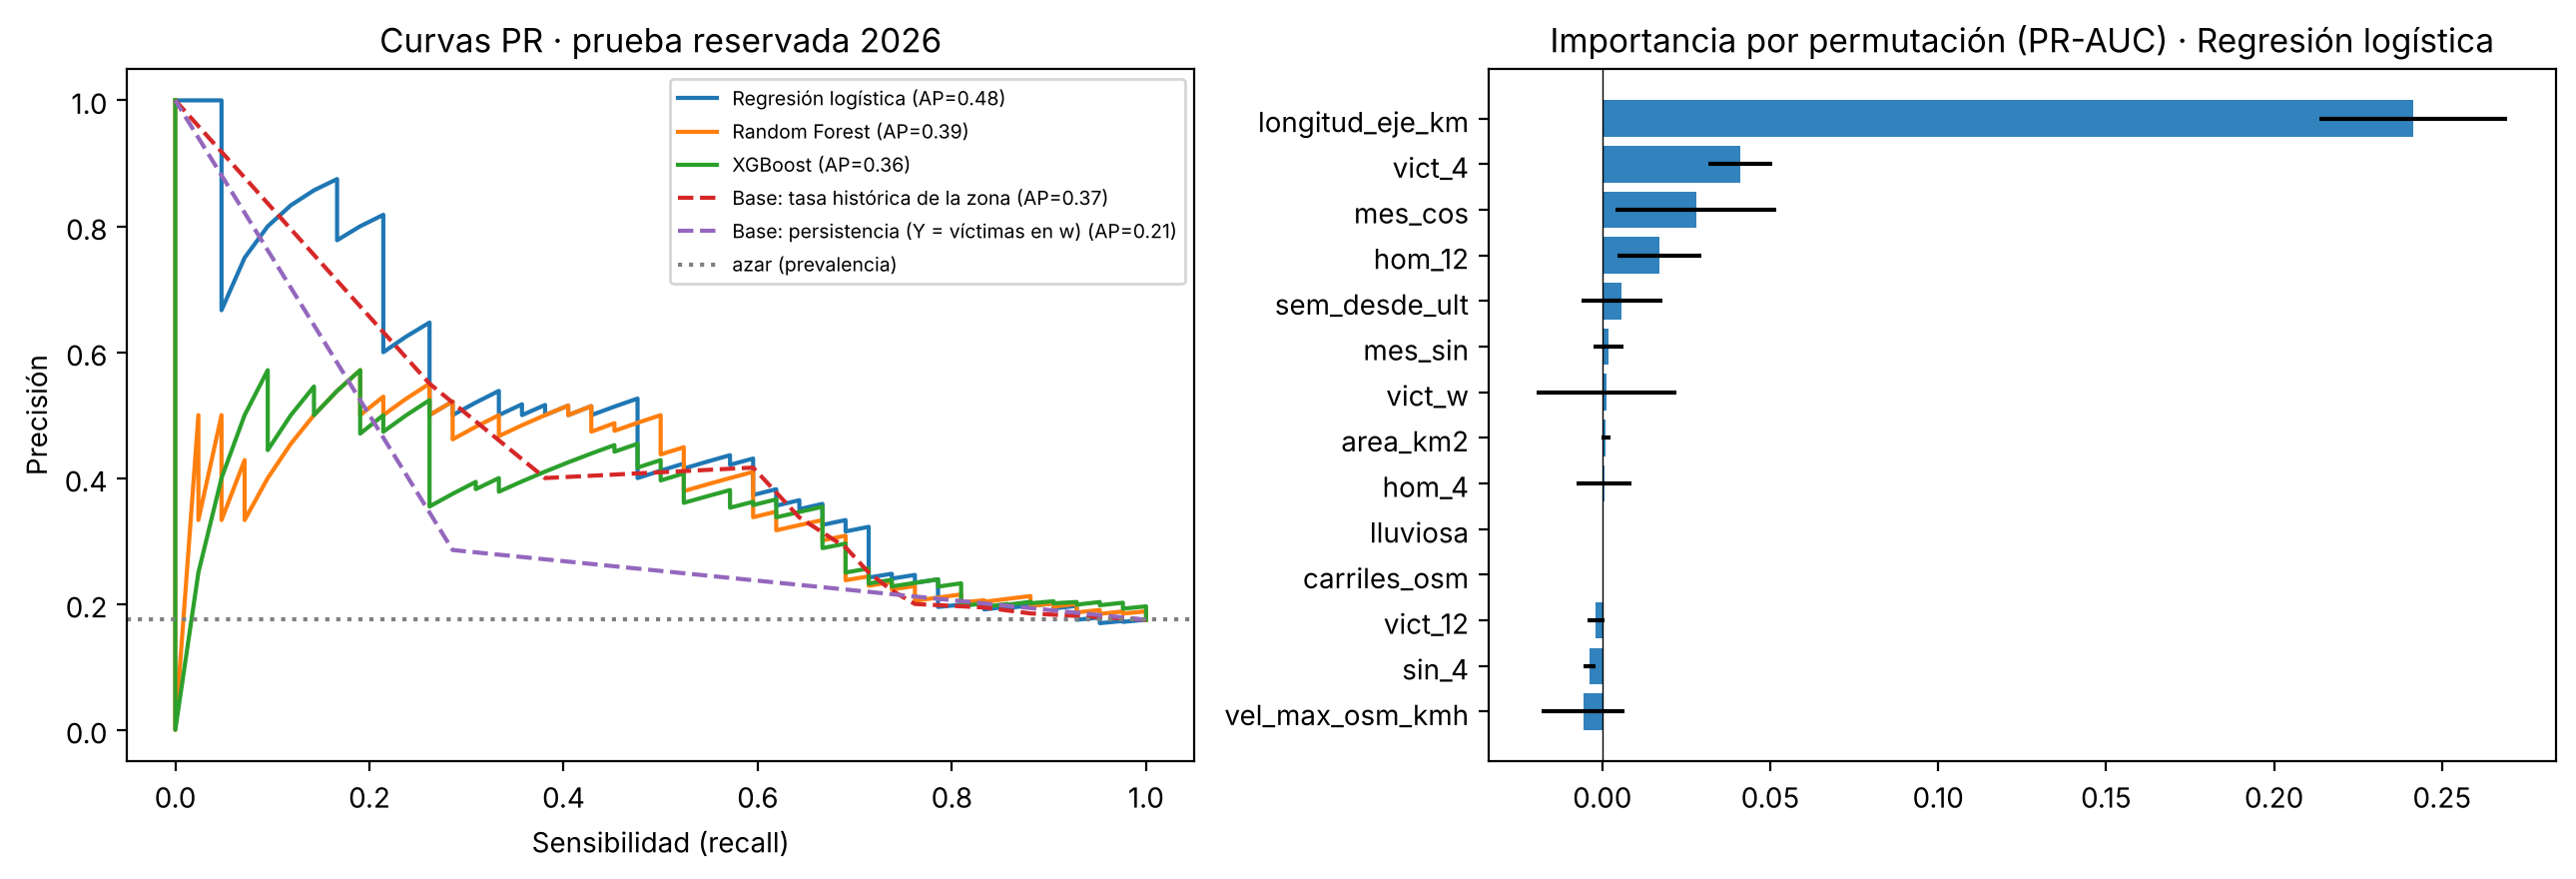

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, p in PROBAS.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rc, pr, ls="--" if nombre.startswith("Base") else "-", label=f"{nombre} (AP={average_precision_score(y_te, p):.2f})")
axes[0].axhline(y_te.mean(), c="grey", ls=":", label="azar (prevalencia)")
axes[0].set_xlabel("Sensibilidad (recall)"); axes[0].set_ylabel("Precisión"); axes[0].set_title("Curvas PR · prueba reservada 2026")
axes[0].legend(fontsize=7)

mejor = COMPARATIVA.drop(index=[i for i in COMPARATIVA.index if i.startswith("Base")]).PR_AUC.idxmax()
imp = permutation_importance(modelos_fin[mejor], te[FEATURES], y_te, scoring="average_precision", n_repeats=20, random_state=SEMILLA)
orden_imp = np.argsort(imp.importances_mean)
axes[1].barh(np.array(FEATURES)[orden_imp], imp.importances_mean[orden_imp], xerr=imp.importances_std[orden_imp], color="#3182bd")
axes[1].set_title(f"Importancia por permutación (PR-AUC) · {mejor}"); axes[1].axvline(0, c="k", lw=0.5)
plt.tight_layout(); plt.savefig(SALIDA_C / "urb04_curvas_pr_importancia.png", dpi=130); plt.show()

## C.6 · Exportación y lectura de resultados

In [10]:
FICHA = pd.DataFrame([
    ("pregunta", "¿Ocurrirá al menos un siniestro con víctimas en la zona la próxima semana?"),
    ("tipo", "ocurrencia (clasificación binaria)"), ("unidad", "zona PER-Z## × semana ISO"),
    ("objetivo", "Y(z, w+1) = 1 si hay ≥ 1 siniestro ATM con lesionados o fallecidos en la semana w+1"),
    ("horizonte", "1 semana"), ("fuente", "ATM (siniestros_via_perimetral_guayaquil.csv, deduplicado por código)"),
    ("periodo", f"{DATA.semana_objetivo.min().date()} a {DATA.semana_objetivo.max().date()}"),
    ("prevalencia", f"{DATA.y.mean():.3f}"), ("n_caracteristicas", len(FEATURES)), ("EPV_entrenamiento", round(EPV, 1)),
    ("tipo_dato", "real (evaluación retrospectiva exploratoria, no validación operativa)"),
], columns=["campo", "valor"])
FICHA.to_csv(SALIDA_C / "urb04_ficha_variable_objetivo.csv", index=False, encoding="utf-8-sig")
PROTOCOLO = particion.assign(uso=["ajuste de modelos", "umbral y comparación", "evaluación final única"])
PROTOCOLO.to_csv(SALIDA_C / "urb04_protocolo_particion.csv", index=False, encoding="utf-8-sig")
COMPARATIVA.to_csv(SALIDA_C / "urb04_tabla_comparativa_modelos.csv", encoding="utf-8-sig")
CV.to_csv(SALIDA_C / "urb04_validacion_cruzada_temporal.csv", index=False, encoding="utf-8-sig")
DATA[["id_zona", "semana", "semana_objetivo", *FEATURES, "y"]].astype({"semana": str}).to_csv(
    SALIDA_C / "urb04_dataset_zona_semana.csv", index=False, encoding="utf-8-sig")

ganan = COMPARATIVA[~COMPARATIVA.index.str.startswith("Base") & COMPARATIVA.supera_mejor_base].index.tolist()
print("Modelos que superan a la mejor línea base en PR-AUC (prueba):", ganan or "ninguno")
print(f"Mejor modelo por PR-AUC en prueba: {mejor}")
print("Lectura: con un solo corredor, 12 zonas y ~21 semanas de prueba, las diferencias entre modelos deben juzgarse con "
      "los intervalos de confianza y la desviación de la validación cruzada. Si los intervalos se solapan, no hay un ganador claro.")

Modelos que superan a la mejor línea base en PR-AUC (prueba): ['Regresión logística', 'Random Forest']
Mejor modelo por PR-AUC en prueba: Regresión logística
Lectura: con un solo corredor, 12 zonas y ~21 semanas de prueba, las diferencias entre modelos deben juzgarse con los intervalos de confianza y la desviación de la validación cruzada. Si los intervalos se solapan, no hay un ganador claro.


## C.7 · Entregables y limitaciones

| Entregable mínimo (auditoría) | Archivo en `salidas_complementarias/` |
|---|---|
| Ficha de variable objetivo | `urb04_ficha_variable_objetivo.csv` (+ tabla de C.1) |
| Tabla comparativa de tres modelos | `urb04_tabla_comparativa_modelos.csv`, `urb04_curvas_pr_importancia.png` |
| Protocolo de evaluación | `urb04_protocolo_particion.csv`, `urb04_validacion_cruzada_temporal.csv` (+ C.3) |
| Notebook exploratorio | esta Parte C; dataset en `urb04_dataset_zona_semana.csv` |

**Limitaciones:**
* Es una evaluación **retrospectiva** sobre un solo corredor: no garantiza el desempeño futuro ni en otras vías.
* Los datos ATM venían duplicados (1 973 filas para 534 siniestros). Los resultados del notebook original y del JSON `risktwin_urb04_output.json`, calculados sobre filas, deben recalcularse.
* No hay variables de tráfico (TPDA), clima diario ni inundaciones reales por zona. Faltan predictores importantes.
* El umbral se eligió maximizando F1 en validación. Para operar convendría fijarlo según la capacidad real de intervención (por ejemplo, k zonas por semana).

---
# Parte B · Notebook original (referencia)

Las celdas siguientes son una **copia del notebook original `URB04_patrones_riesgo_urbano_piloto.ipynb`**. Se conservan para que el equipo
pueda comparar y reutilizar código, pero **no forman parte de la entrega mínima**: la entrega es la Parte C
(arriba). Las celdas de esta parte requieren las mismas dependencias y credenciales que el original
(OSM/Overpass, Supabase, API de LLM, etc.).

**Ajustes puntuales aplicados en esta copia** (marcados en el código con `# [AJUSTE AUDITORÍA]`):

* Celda de parámetros: `BBOX_POR_DEFECTO` acotado al **corredor de la Perimetral**. Se añade la justificación de `MIN_EVENTOS_REALES = 500` (decisión de diseño, no requisito estadístico; la Parte C usa EPV ≥ 10) y la advertencia sobre las filas duplicadas del CSV ATM.


# URB-04 · Detección de patrones de riesgo urbano en datos multimodales
## Notebook piloto (prueba de concepto)

**Proyecto:** Aplicación de inteligencia artificial para detección de patrones de riesgo urbano en datos multimodales (bloque URB-04, proyecto RISKTWIN)
**Institución:** Universidad de Guayaquil · Facultad de Ingeniería Industrial · Sistemas de la Información
**Metodología:** CRISP-ML(Q) + Design Science Research (DSR)

---

### ¿Qué hace este notebook?

Recorre, de punta a punta, el flujo del anteproyecto: **cargar datos de accidentes desde Supabase** (o, si no hay datos suficientes, generar datos sintéticos como *plan B*), construir un dataset multimodal por zona, **comparar tres estrategias de modelado** y producir la salida JSON para una futura API.

| Fase CRISP-ML(Q) | Secciones | Requisitos (REQ) |
|---|---|---|
| 1. Comprensión del negocio y de los datos | 1–4 | — |
| 2. Ingeniería de datos | 5–9 | REQ-01, 02, 03 |
| 3. Ingeniería de modelo | 10–13 | REQ-04, 05, 06 |
| 4. Evaluación | 14–17 | REQ-07, 08, 09 |
| 5. Despliegue (exportación) | 18 | REQ-10 |
| 6. Monitoreo | 19 | — (propuesta) |

> ⚠️ **Aviso importante.** Mientras los datos reales sean insuficientes, las variables de grafo y contexto (y los eventos, si no hay accidentes cargados) son **sintéticos**. Los resultados de este piloto sirven para **validar el pipeline**, no para tomar decisiones operativas. El anteproyecto exige documentar explícitamente este carácter simulado.

## Mapa de correspondencia CRISP-ML(Q) ↔ DSR

| CRISP-ML(Q) | DSR | En este notebook |
|---|---|---|
| Comprensión de los datos | Identificación del problema | Secciones 1–4 |
| Ingeniería de datos / de modelo | Diseño del artefacto | Secciones 5–13 |
| Ingeniería de modelo (entrenamiento) | Demostración | Secciones 10–13 (ejecución del pipeline) |
| Evaluación | Evaluación de la solución | Secciones 14–17 |
| Despliegue y mejora | Comunicación de resultados | Secciones 18–19 |

Cada fase incluye su **control de calidad** (pruebas de esquema y rango, chequeo de *data leakage*, semillas fijas, comparación contra un modelo base).

## 1. Comprensión del negocio (Fase 1)

**Pregunta de investigación.** ¿Qué modelos de aprendizaje automático permiten identificar patrones o clasificar zonas de riesgo urbano a partir de datos multimodales?

**Traducción a un problema de ML.** Dada una zona de la ciudad descrita por variables de cuatro tipos, estimar su **nivel de riesgo futuro** (Bajo, Medio, Alto).

| Tipo de variable | Ejemplos usados en el piloto |
|---|---|
| Geoespaciales | distancia al centro y a la vía principal |
| De grafo | grado, centralidad de intermediación, cercanía |
| Contextuales | densidad poblacional, iluminación, uso de suelo |
| De eventos | accidentes previos, su severidad media y los graves |

**Tres estrategias que se comparan** (diseño experimental del anteproyecto):

1. **Supervisada tradicional:** Random Forest y XGBoost, contra un modelo base ingenuo.
2. **Basada en grafos:** GCN y GraphSAGE, que usan la conectividad de la red urbana.
3. **No supervisada** (si no hay etiquetas): k-means, Spectral Clustering y Node2Vec + K-Means.

**Cómo se define la etiqueta (sin fuga de datos).** Los accidentes anteriores a una *fecha de corte* se usan como **variables**; los posteriores se usan para construir la **etiqueta** (Bajo = 50 % de zonas con menor severidad acumulada, Medio = siguiente 30 %, Alto = 20 % superior). Así el modelo predice el futuro con información del pasado.

**Supuestos y límites éticos/legales** (a documentar en la tesis): los datos son agregados por zona y no contienen información personal; las zonas sin registros **no** se interpretan como zonas sin riesgo (puede haber subregistro); la clasificación es una herramienta de apoyo, no un veredicto sobre barrios ni personas.

## 2. Preparación del entorno

Se instalan solo las librerías que Colab no trae: `supabase` (acceso a PostgreSQL), `shap`, `gensim` (para Node2Vec), `esda` y `libpysal` (índice de Moran). `torch`, `xgboost`, `scikit-learn` y `networkx` ya vienen instalados.

Las redes GCN y GraphSAGE se implementan **directamente en PyTorch** (con matrices de adyacencia), sin depender de PyTorch Geometric. Para ciudades con miles de zonas conviene migrar a PyG o DGL.

In [ ]:
!pip -q install supabase shap gensim esda libpysal

In [ ]:
import os, json, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import requests

from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, average_precision_score, silhouette_score,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

### 2.1 Parámetros del piloto

Todo lo ajustable está en esta celda. Reemplaza `TABLA_ACCIDENTES` por el nombre real de tu tabla en Supabase.

In [ ]:
# --- Reproducibilidad (CRISP-ML(Q): semillas fijas) ---------------------------
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# --- Zonas: cuadrícula de FILAS x COLS (cada celda = una zona/nodo del grafo) --
FILAS, COLS = 16, 16                       # 256 zonas
BBOX_POR_DEFECTO = (-79.9600, -2.2425, -79.9100, -2.0730)   # [AJUSTE AUDITORÍA] corredor Vía Perimetral (COMUN)

# --- Origen de datos ------------------------------------------------------------
USAR_DATOS_REALES = True      # intenta cargar accidentes desde Supabase; si falla -> sintéticos (plan B)
METODO_CARGA = "sdk"          # "sdk" (cliente oficial) o "rest" (solicitudes HTTP)
TABLA_ACCIDENTES = "nombreDetabla"          # <- nombre de tu tabla de accidentes
MAPA_COLUMNAS = {}            # si tus columnas se llaman distinto: {"latitud": "lat", "longitud": "lon", "heridos": "severidad"}
MIN_EVENTOS_REALES = 500      # por debajo de esto se considera insuficiente y se usan datos sintéticos
# [AJUSTE AUDITORÍA] 500 es una decisión de diseño de este piloto, NO un requisito estadístico universal.
# La Parte C usa un criterio explícito: eventos por variable (EPV) >= 10 positivos por característica.
# Además, el CSV ATM de la Perimetral tiene 1 973 filas pero solo 534 siniestros únicos: deduplicar por
# código SINIESTROS antes de comparar con este umbral (ver cargar_eventos_reales() en la Parte C).

# --- Modelado -------------------------------------------------------------------
CLASES = ["Bajo", "Medio", "Alto"]
PCT_CORTES = [0, 0.50, 0.80, 1.0]   # 50 % Bajo, 30 % Medio, 20 % Alto (clases desbalanceadas, como en la realidad)
TEST_SIZE = 0.30
N_CLUSTERS = 3
MODELO_EXPORT = "xgboost"           # "xgboost" o "random_forest": modelo que se exporta a la API
GUARDAR_EN_SUPABASE = False         # True -> sube el resultado final a la tabla TABLA_RESULTADOS
TABLA_RESULTADOS = "riesgo_zonas"

OUT = Path("salidas_urb04"); OUT.mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, force=True, format="%(asctime)s | %(levelname)s | %(message)s",
                    handlers=[logging.FileHandler(OUT / "ejecucion.log", mode="w", encoding="utf-8"), logging.StreamHandler()])
log = logging.getLogger("urb04")

## 3. Carga de datos disponibles desde Supabase

Supabase publica cada tabla de PostgreSQL mediante una API. Se ofrecen **los dos métodos** de acceso (HTTP con `requests` y SDK oficial); ambos **paginan** los resultados, porque Supabase devuelve como máximo **1000 filas por consulta** y una tabla más grande quedaría truncada sin avisar.

**Antes de ejecutar:** en Colab, panel izquierdo → 🔑 *Secretos*, crea `SUPABASE_URL` y `SUPABASE_KEY` y activa el acceso para este notebook. Así las credenciales no quedan escritas en el código (si compartes el notebook o lo subes a GitHub, no se filtran). Para solo leer basta la clave `anon` con una política de lectura (RLS) en la tabla.

**Columnas esperadas en la tabla de accidentes:**

| Columna | Obligatoria | Descripción |
|---|:-:|---|
| `fecha` | Sí | Fecha (y hora, si está) del accidente |
| `lat`, `lon` | Sí | Coordenadas en grados decimales (si se llaman distinto, usa `MAPA_COLUMNAS`) |
| `severidad` | No | Número 1–3, o texto (leve / herido / fallecido). Si falta, todos los accidentes pesan 1 |

In [ ]:
def obtener_credenciales():
    # Lee los Secretos de Colab o variables de entorno. Devuelve (None, None) si no están.
    try:
        from google.colab import userdata
        return userdata.get("SUPABASE_URL"), userdata.get("SUPABASE_KEY")
    except Exception:
        return os.environ.get("SUPABASE_URL"), os.environ.get("SUPABASE_KEY")

SUPABASE_URL, SUPABASE_KEY = obtener_credenciales()

# ==========================================
# MÉTODO A: solicitudes HTTP básicas (requests), con paginación
# ==========================================
def cargar_datos_api_rest(tabla=TABLA_ACCIDENTES, tam_pagina=1000):
    headers = {"apikey": SUPABASE_KEY, "Authorization": f"Bearer {SUPABASE_KEY}"}
    filas, offset = [], 0
    print("📡 Consultando API REST de Supabase...")
    while True:
        url = f"{SUPABASE_URL}/rest/v1/{tabla}?select=*&limit={tam_pagina}&offset={offset}"
        resp = requests.get(url, headers=headers, timeout=60)
        if resp.status_code != 200:
            print(f"❌ Error en la llamada API: {resp.status_code}\n{resp.text}")
            return None
        lote = resp.json()
        filas.extend(lote)
        if len(lote) < tam_pagina:
            break
        offset += tam_pagina
    return pd.DataFrame(filas)

# ==========================================
# MÉTODO B: cliente SDK oficial de Supabase, con paginación
# ==========================================
def cargar_datos_sdk(tabla=TABLA_ACCIDENTES, tam_pagina=1000):
    print("📡 Conectando mediante SDK oficial...")
    try:
        from supabase import create_client
        cliente = create_client(SUPABASE_URL, SUPABASE_KEY)
        filas, desde = [], 0
        while True:
            r = cliente.table(tabla).select("*").range(desde, desde + tam_pagina - 1).execute()
            filas.extend(r.data)
            if len(r.data) < tam_pagina:
                break
            desde += tam_pagina
        return pd.DataFrame(filas)
    except Exception as e:
        print(f"❌ Error usando el SDK: {e}")
        return None

def cargar_accidentes():
    # Devuelve un DataFrame con los accidentes, o None si no se puede (se usará el plan B sintético).
    if not USAR_DATOS_REALES:
        print("ℹ️ USAR_DATOS_REALES=False -> se usarán datos sintéticos.")
        return None
    if not SUPABASE_URL or not SUPABASE_KEY:
        print("⚠️ No hay credenciales (SUPABASE_URL / SUPABASE_KEY en Secretos). Se usarán datos sintéticos.")
        return None
    return cargar_datos_api_rest() if METODO_CARGA == "rest" else cargar_datos_sdk()

# --- Prueba de carga ---
df_accidentes = cargar_accidentes()
if df_accidentes is not None:
    print(f"✅ {len(df_accidentes):,} filas cargadas. Columnas: {list(df_accidentes.columns)}")
    display(df_accidentes.head())

## 4. Preparación de los eventos reales (control de calidad de esquema y rango)

Si se cargaron accidentes, se **validan** (columnas obligatorias, coordenadas dentro de Ecuador, fechas válidas) y se normaliza la severidad a la escala 1–3. Si no hay datos suficientes, el notebook continúa con el plan B (sección 7).

In [ ]:
def normalizar_severidad(s):
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.8:
        return num.fillna(1).clip(1, 3).round().astype(int)
    t = s.astype(str).str.lower()
    out = pd.Series(1, index=s.index)
    out[t.str.contains("herid|lesion|grave")] = 2
    out[t.str.contains("fallec|muert|fatal|mortal")] = 3
    return out

def preparar_eventos_reales(df):
    d = df.rename(columns=MAPA_COLUMNAS).copy()
    faltan = {"fecha", "lat", "lon"} - set(d.columns)
    if faltan:
        raise ValueError(f"Faltan columnas {faltan}. Usa MAPA_COLUMNAS para renombrarlas. Columnas actuales: {list(d.columns)}")
    n0 = len(d)
    d["fecha"] = pd.to_datetime(d["fecha"], errors="coerce", utc=True).dt.tz_localize(None)
    for c in ["lat", "lon"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.dropna(subset=["fecha", "lat", "lon"])
    d = d[d["lat"].between(-5.1, 1.5) & d["lon"].between(-92.5, -75.0)]       # rango plausible para Ecuador
    d["sev"] = normalizar_severidad(d["severidad"]) if "severidad" in d.columns else 1
    d["hora"] = d["fecha"].dt.hour + d["fecha"].dt.minute / 60
    log.info("Eventos reales: %d de %d filas válidas (%.1f%% descartadas)", len(d), n0, 100 * (1 - len(d) / max(n0, 1)))
    return d[["fecha", "lat", "lon", "sev", "hora"]].reset_index(drop=True)

ev_real = None
if df_accidentes is not None and len(df_accidentes) > 0:
    try:
        ev_real = preparar_eventos_reales(df_accidentes)
    except Exception as e:
        print("❌ No se pudieron preparar los accidentes:", e)

USAR_REAL = ev_real is not None and len(ev_real) >= MIN_EVENTOS_REALES
if ev_real is not None and not USAR_REAL:
    print(f"⚠️ Solo hay {len(ev_real)} eventos válidos (mínimo {MIN_EVENTOS_REALES}): se usará el plan B sintético.")
print("Fuente de eventos para el modelado ->", "REAL (Supabase)" if USAR_REAL else "SINTÉTICA (plan B)")
log.info("Fuente de eventos: %s", "real" if USAR_REAL else "sintetica")
if USAR_REAL:
    display(ev_real.describe(include="all").T.round(3))

## 5. Zonas y grafo urbano (REQ-01 · variables geoespaciales y de grafo)

En el proyecto, el grafo urbano llega como insumo de otro bloque (CSV/JSON/GraphML). Aquí se **simula**: cada zona es un nodo; hay aristas con las zonas vecinas y algunas **avenidas** (atajos) que conectan zonas lejanas, para que la centralidad sea informativa.

De cada nodo se calculan: **grado**, **centralidad de intermediación** y **cercanía**.

In [ ]:
# Ventana geográfica: si hay datos reales, se ajusta a donde están los accidentes
if USAR_REAL:
    q = ev_real[["lon", "lat"]].quantile([0.01, 0.99])
    pad_x, pad_y = 0.02 * (q.loc[0.99, "lon"] - q.loc[0.01, "lon"]), 0.02 * (q.loc[0.99, "lat"] - q.loc[0.01, "lat"])
    BBOX = (q.loc[0.01, "lon"] - pad_x, q.loc[0.01, "lat"] - pad_y, q.loc[0.99, "lon"] + pad_x, q.loc[0.99, "lat"] + pad_y)
else:
    BBOX = BBOX_POR_DEFECTO
lon_min, lat_min, lon_max, lat_max = BBOX
N = FILAS * COLS
CELDA_M = 111_320 * (lat_max - lat_min) / FILAS         # tamaño aproximado de una zona (m)
print(f"Zonas: {N} | tamaño aproximado de zona: {CELDA_M:,.0f} m")

zonas = pd.DataFrame({"zona": np.arange(N)})
zonas["fila"], zonas["col"] = zonas["zona"] // COLS, zonas["zona"] % COLS
zonas["lat"] = lat_min + (zonas["fila"] + 0.5) * (lat_max - lat_min) / FILAS
zonas["lon"] = lon_min + (zonas["col"] + 0.5) * (lon_max - lon_min) / COLS
zonas = zonas.set_index("zona", drop=False)

def construir_grafo(filas, cols, rng, n_avenidas=3):
    G = nx.grid_2d_graph(filas, cols)
    G = nx.relabel_nodes(G, {(r, c): r * cols + c for r in range(filas) for c in range(cols)})
    av_f = rng.choice(filas, n_avenidas, replace=False)
    av_c = rng.choice(cols, n_avenidas, replace=False)
    for r in av_f:                                      # avenidas horizontales: atajos cada 3 zonas
        for c in range(0, cols - 3, 3):
            G.add_edge(int(r) * cols + c, int(r) * cols + c + 3)
    for c in av_c:                                      # avenidas verticales
        for r in range(0, filas - 3, 3):
            G.add_edge(r * cols + int(c), (r + 3) * cols + int(c))
    return G, av_f, av_c

G, av_f, av_c = construir_grafo(FILAS, COLS, rng)
assert nx.is_connected(G)
print(f"Grafo: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas")

Z = pd.DataFrame(index=zonas.index)
Z["grado"] = pd.Series(dict(G.degree()))
Z["intermediacion"] = pd.Series(nx.betweenness_centrality(G))
Z["cercania"] = pd.Series(nx.closeness_centrality(G))
# Variables geoespaciales: distancias (en metros, aproximadas)
Z["dist_centro_m"] = np.hypot(zonas["fila"] - (FILAS - 1) / 2, zonas["col"] - (COLS - 1) / 2) * CELDA_M
Z["dist_via_principal_m"] = np.minimum(np.abs(zonas["fila"].values[:, None] - av_f[None, :]).min(1),
                                       np.abs(zonas["col"].values[:, None] - av_c[None, :]).min(1)) * CELDA_M
Z.describe().T.round(3)

## 6. Variables contextuales (sintéticas)

Densidad poblacional, iluminación y uso de suelo también llegan de otro bloque. Se simulan con una lógica urbana simple (el centro es más denso, más iluminado y más comercial) y se les **inyecta un 5 % de valores faltantes** para ejercitar el tratamiento de datos incompletos (variable moderadora «calidad y disponibilidad de datos»).

In [ ]:
def generar_contexto(zonas, rng):
    d = Z["dist_centro_m"].values / Z["dist_centro_m"].max()                 # 0 en el centro, 1 en la periferia
    densidad = np.clip(rng.lognormal(4.2, 0.35, N) * (1.6 - d), 5, None)      # hab/ha
    ilum = np.clip(0.85 - 0.5 * d + rng.normal(0, 0.12, N), 0, 1)              # índice 0-1
    uso = np.select([d < 0.25, d < 0.55, d < 0.85], ["comercial", "mixto", "residencial"], default="industrial")
    ctx = pd.DataFrame({"densidad_hab_ha": densidad, "iluminacion": ilum, "uso_suelo": uso}, index=zonas.index)
    for col in ["densidad_hab_ha", "iluminacion"]:                            # 5 % de faltantes
        ctx.loc[rng.choice(N, int(0.05 * N), replace=False), col] = np.nan
    return ctx

ctx = generar_contexto(zonas, rng)
Z = Z.join(ctx)
faltantes = Z.isna().mean().mul(100).round(1)
print("% de datos faltantes por variable (variable moderadora):"); print(faltantes[faltantes > 0].to_string())
Z.head()

## 7. Eventos: reales o sintéticos (REQ-02 · plan B)

Si no hubo accidentes reales suficientes, se **generan eventos sintéticos** cuya probabilidad de ocurrir en una zona depende de un **riesgo latente** (más centralidad y densidad, menos iluminación, cercanía a avenidas) con un efecto de **contagio espacial** entre zonas vecinas. Cada evento tiene fecha (2023-01 a 2026-06), hora, severidad y coordenadas.

> El generador existe también cuando hay datos reales: se usa en la sección 8 para **validar con Kolmogorov-Smirnov** que lo sintético se parece a lo real.

In [ ]:
A = nx.to_numpy_array(G, nodelist=range(N))
A_media = A / A.sum(1, keepdims=True)                        # promedio de vecinos

def zscore(s):
    s = pd.Series(s, dtype=float)
    return ((s - s.mean()) / s.std()).fillna(0).values

def riesgo_latente(Z, rng):
    base = (0.6 * zscore(Z["intermediacion"]) + 0.5 * zscore(Z["densidad_hab_ha"].fillna(Z["densidad_hab_ha"].median()))
            - 0.5 * zscore(Z["iluminacion"].fillna(Z["iluminacion"].median())) - 0.3 * zscore(Z["dist_via_principal_m"])
            + rng.normal(0, 0.5, N))
    return zscore(base + 0.6 * (A_media @ base))             # contagio espacial entre vecinos

def generar_eventos_sinteticos(latente, n_eventos=6000, rng=rng, desplazar_hora=0.0):
    p = np.exp(latente); p /= p.sum()
    zona = rng.choice(N, n_eventos, p=p)
    fecha = pd.Timestamp("2023-01-01") + pd.to_timedelta(rng.integers(0, 1277, n_eventos), unit="D")
    comp = rng.choice(3, n_eventos, p=[0.35, 0.40, 0.25])                    # horas pico: mañana, tarde, uniforme
    hora = np.where(comp == 0, rng.normal(8, 1.5, n_eventos), np.where(comp == 1, rng.normal(18, 2, n_eventos), rng.uniform(0, 24, n_eventos)))
    hora = (hora + desplazar_hora) % 24
    f, c = zonas["fila"].values[zona], zonas["col"].values[zona]
    return pd.DataFrame({"fecha": fecha, "hora": hora, "sev": rng.choice([1, 2, 3], n_eventos, p=[0.70, 0.22, 0.08]),
                         "lat": lat_min + (f + rng.uniform(0, 1, n_eventos)) * (lat_max - lat_min) / FILAS,
                         "lon": lon_min + (c + rng.uniform(0, 1, n_eventos)) * (lon_max - lon_min) / COLS, "zona": zona})

def asignar_zona(ev):
    r = np.floor((ev["lat"] - lat_min) / (lat_max - lat_min) * FILAS).astype(int)
    c = np.floor((ev["lon"] - lon_min) / (lon_max - lon_min) * COLS).astype(int)
    ok = (r >= 0) & (r < FILAS) & (c >= 0) & (c < COLS)
    out = ev[ok].copy(); out["zona"] = (r[ok] * COLS + c[ok]).astype(int)
    return out

latente = riesgo_latente(Z, rng)
ev_sint = generar_eventos_sinteticos(latente)

if USAR_REAL:
    eventos = asignar_zona(ev_real)
    log.info("Eventos reales asignados a zonas: %d de %d", len(eventos), len(ev_real))
else:
    eventos = ev_sint
print(f"Eventos usados para el modelado: {len(eventos):,} ({'reales' if USAR_REAL else 'sintéticos'}) | rango de fechas: {eventos['fecha'].min().date()} → {eventos['fecha'].max().date()}")

## 8. Validación de datos sintéticos con Kolmogorov-Smirnov (REQ-03)

La prueba K-S compara dos muestras y contrasta la hipótesis nula **H0: ambas provienen de la misma distribución**.

- Si `p > 0,05` **no se rechaza H0** → no hay evidencia de que lo sintético difiera de lo real.
- Si `p ≤ 0,05` se rechaza H0 → la distribución sintética no es representativa y hay que recalibrar el generador.

Dos casos:

- **Con accidentes reales:** se compara la **hora del día** y el **peso de cada zona** (proporción de accidentes) real vs. sintético.
- **Sin accidentes reales (este piloto):** no hay referencia real, así que se hace una **demostración de la prueba**: sintético vs. otra muestra sintética (debería no rechazarse) y vs. una muestra con la hora desplazada +4 h (debería rechazarse). Esto solo comprueba que el procedimiento funciona.

In [ ]:
def validar_ks(ref, sint, nombre, alfa=0.05):
    D, p = ks_2samp(ref, sint)
    return {"variable": nombre, "D": round(D, 3), "p_valor": round(p, 4),
            "decision": "No se rechaza H0 (similar)" if p > alfa else "Se rechaza H0 (distinta)"}

peso_zona = lambda ev: (ev.groupby("zona").size().reindex(range(N)).fillna(0) / len(ev)).values

if USAR_REAL:
    ref, nombre_ref = eventos, "real"
    filas_ks = [validar_ks(ref["hora"], ev_sint["hora"], "hora del día (real vs sintético)"),
                validar_ks(peso_zona(ref), peso_zona(ev_sint), "peso de cada zona (real vs sintético)")]
else:
    ev_ref = generar_eventos_sinteticos(latente, rng=np.random.default_rng(SEED + 1))
    ev_mal = generar_eventos_sinteticos(latente, rng=np.random.default_rng(SEED + 2), desplazar_hora=4)
    filas_ks = [validar_ks(ev_ref["hora"], ev_sint["hora"], "DEMO: hora sintética vs otra muestra sintética"),
                validar_ks(ev_mal["hora"], ev_sint["hora"], "DEMO: hora desplazada +4 h vs sintética")]

tabla_ks = pd.DataFrame(filas_ks)
tabla_ks.to_csv(OUT / "validacion_ks.csv", index=False)
log.info("K-S: %s", tabla_ks.to_dict("records"))
tabla_ks

In [ ]:
# Visual: comparación de distribuciones acumuladas (hora del día)
fig, ax = plt.subplots(figsize=(6, 3.2))
a = np.sort((eventos if USAR_REAL else ev_ref)["hora"]); b = np.sort(ev_sint["hora"])
ax.plot(a, np.linspace(0, 1, len(a)), label="referencia (real)" if USAR_REAL else "referencia (sintética)")
ax.plot(b, np.linspace(0, 1, len(b)), label="sintética")
if not USAR_REAL:
    c_ = np.sort(ev_mal["hora"]); ax.plot(c_, np.linspace(0, 1, len(c_)), "--", label="desplazada +4 h")
ax.set_xlabel("hora del día"); ax.set_ylabel("distribución acumulada"); ax.legend(); ax.set_title("Prueba K-S: CDF empíricas")
plt.tight_layout(); plt.show()

## 9. Dataset analítico: variables y etiqueta (REQ-01) con control de fuga de datos

Se define una **fecha de corte** en el percentil 60 de las fechas de los eventos:

- Accidentes **antes** del corte → variables de eventos (`ev_previos`, `sev_media_prev`, `graves_prev`).
- Accidentes **después** del corte → etiqueta de riesgo futuro (por severidad acumulada).

Como la etiqueta se construye con información posterior a las variables, **no hay fuga de datos** (*data leakage*).

In [ ]:
corte = eventos["fecha"].quantile(0.60).normalize()
print("Fecha de corte:", corte.date())

def construir_dataset(ev, Z, corte):
    pas, fut = ev[ev["fecha"] < corte], ev[ev["fecha"] >= corte]
    f = pd.DataFrame(index=Z.index)
    f["ev_previos"] = pas.groupby("zona").size()
    f["graves_prev"] = pas[pas["sev"] >= 2].groupby("zona").size()
    f["sev_media_prev"] = pas.groupby("zona")["sev"].mean()
    f[["ev_previos", "graves_prev", "sev_media_prev"]] = f[["ev_previos", "graves_prev", "sev_media_prev"]].fillna(0)
    score_fut = fut.groupby("zona")["sev"].sum().reindex(Z.index).fillna(0)       # severidad acumulada futura
    pct = score_fut.rank(method="first", pct=True)
    y = pd.cut(pct, PCT_CORTES, labels=[0, 1, 2], include_lowest=True).astype(int)
    return Z.join(f), y, score_fut

datos, y_s, score_fut = construir_dataset(eventos, Z, corte)
y = y_s.values

# Control de calidad: esquema y rangos
assert len(datos) == N and set(np.unique(y)) <= {0, 1, 2}
assert datos["iluminacion"].dropna().between(0, 1).all() and (datos["ev_previos"] >= 0).all()
assert eventos[eventos["fecha"] < corte]["fecha"].max() < corte <= eventos[eventos["fecha"] >= corte]["fecha"].min()   # sin fuga temporal

print("Distribución de la etiqueta (clases desbalanceadas):")
print(pd.Series(y).map(dict(enumerate(CLASES))).value_counts().reindex(CLASES).to_string())
datos.head()

## 10. Selección de variables y partición de datos

1. **División** estratificada: 70 % entrenamiento / 30 % prueba.
2. **Imputación** por mediana, ajustada **solo con entrenamiento** (para no filtrar información de prueba).
3. **Selección de variables:** se descartan las de baja varianza y las redundantes (correlación > 0,95).
4. `uso_suelo` se convierte a variables binarias (*one-hot*).

In [ ]:
Xdf = pd.get_dummies(datos, columns=["uso_suelo"], dtype=float)
idx_tr, idx_te = train_test_split(np.arange(N), test_size=TEST_SIZE, stratify=y, random_state=SEED)

imp = SimpleImputer(strategy="median").fit(Xdf.iloc[idx_tr])
X_imp = pd.DataFrame(imp.transform(Xdf), columns=Xdf.columns, index=Xdf.index)

bajos = X_imp.iloc[idx_tr].var()[lambda v: v < 1e-8].index.tolist()
corr = X_imp.iloc[idx_tr].drop(columns=bajos).corr().abs()
sup = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redund = [c for c in sup.columns if (sup[c] > 0.95).any()]
FEATURES = [c for c in X_imp.columns if c not in bajos + redund]
X = X_imp[FEATURES]

print(f"Entrenamiento: {len(idx_tr)} zonas | Prueba: {len(idx_te)} zonas")
print("Descartadas por baja varianza:", bajos or "ninguna", "| por redundancia:", redund or "ninguna")
print(f"Variables finales ({len(FEATURES)}):", FEATURES)

fig, ax = plt.subplots(figsize=(7, 5.5))
cm = X.iloc[idx_tr].corr()
im = ax.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=7)
plt.colorbar(im, shrink=0.7); ax.set_title("Correlación entre variables (entrenamiento)"); plt.tight_layout(); plt.show()

## 11. Métricas y modelo base (Fase 3 · REQ-04, REQ-07)

Como las clases están desbalanceadas, la *accuracy* sola engaña. Se reportan tres métricas:

- **Accuracy:** aciertos globales.
- **F1-Score macro:** promedio del F1 por clase, sin ponderar por su tamaño.
- **PR-AUC macro:** área bajo la curva precisión-recall (uno contra todos), más informativa que ROC con clases raras.

Todo modelo se compara contra un **modelo base ingenuo** (predice siempre la clase mayoritaria): si no lo supera claramente, no aporta valor.

In [ ]:
resultados, probas = [], {}

def evaluar(nombre, proba, familia):
    y_te = y[idx_te]; p = proba[idx_te]; pred = p.argmax(1)
    yb = label_binarize(y_te, classes=[0, 1, 2])
    fila = {"modelo": nombre, "familia": familia, "accuracy": accuracy_score(y_te, pred),
            "f1_macro": f1_score(y_te, pred, average="macro"), "pr_auc_macro": average_precision_score(yb, p, average="macro")}
    resultados.append(fila); probas[nombre] = proba
    return fila

def cv_metricas(crear, k=5):
    # Validación cruzada estratificada sobre entrenamiento (control de sobreajuste y estabilidad)
    f1s = []
    for a, b in StratifiedKFold(k, shuffle=True, random_state=SEED).split(X.iloc[idx_tr], y[idx_tr]):
        m = crear(); xa, ya = X.iloc[idx_tr].iloc[a], y[idx_tr][a]
        m.fit(xa, ya, sample_weight=compute_sample_weight("balanced", ya)) if isinstance(m, XGBClassifier) else m.fit(xa, ya)
        f1s.append(f1_score(y[idx_tr][b], m.predict(X.iloc[idx_tr].iloc[b]), average="macro"))
    return np.mean(f1s), np.std(f1s)

base = DummyClassifier(strategy="prior").fit(X.iloc[idx_tr], y[idx_tr])
evaluar("Base ingenuo (mayoritaria)", base.predict_proba(X), "base")
pd.DataFrame(resultados).round(3)

## 12. Modelos supervisados: Random Forest y XGBoost (REQ-04)

Ambos usan **ponderación de clases** para compensar el desbalanceo. Se reporta además el F1 macro en validación cruzada (media ± desviación) como medida de **estabilidad**.

In [ ]:
crear_rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=SEED)
crear_xgb = lambda: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.9,
                                  objective="multi:softprob", eval_metric="mlogloss", n_jobs=-1, random_state=SEED)

rf = crear_rf().fit(X.iloc[idx_tr], y[idx_tr])
xgb = crear_xgb().fit(X.iloc[idx_tr], y[idx_tr], sample_weight=compute_sample_weight("balanced", y[idx_tr]))
evaluar("Random Forest", rf.predict_proba(X), "supervisado")
evaluar("XGBoost", xgb.predict_proba(X), "supervisado")

cv = {n: cv_metricas(f) for n, f in [("Random Forest", crear_rf), ("XGBoost", crear_xgb)]}
for n, (m, s) in cv.items():
    print(f"{n}: F1 macro en validación cruzada (5 pliegues) = {m:.3f} ± {s:.3f}")
pd.DataFrame(resultados).round(3)

## 13. Modelo basado en grafos: GCN y GraphSAGE (REQ-05)

Los modelos de grafos clasifican cada zona usando **sus variables y las de sus vecinas** en la red urbana:

- **GCN:** cada capa promedia (con normalización simétrica) las variables de la zona y sus vecinas.
- **GraphSAGE:** concatena las variables de la zona con el **promedio de sus vecinas** y aprende una transformación.

Es un enfoque **transductivo**: durante el entrenamiento el modelo ve las variables de todas las zonas, pero **solo las etiquetas de entrenamiento**. Se repite con 5 semillas para medir la estabilidad.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F

sc_g = StandardScaler().fit(X.iloc[idx_tr])                         # escalado ajustado solo con entrenamiento
Xg = torch.tensor(sc_g.transform(X), dtype=torch.float32)
A_hat = A + np.eye(N); Dm = np.diag(A_hat.sum(1) ** -0.5)
A_gcn = torch.tensor(Dm @ A_hat @ Dm, dtype=torch.float32)          # normalización simétrica con auto-conexión
A_sage = torch.tensor(A_media, dtype=torch.float32)                 # promedio de vecinos

class GCN(nn.Module):
    def __init__(s, d_in, d_h, n_cls, p=0.3):
        super().__init__(); s.l1, s.l2, s.p = nn.Linear(d_in, d_h), nn.Linear(d_h, n_cls), p
    def forward(s, X, A):
        h = F.dropout(F.relu(A @ s.l1(X)), s.p, s.training)
        return A @ s.l2(h)

class GraphSAGE(nn.Module):
    def __init__(s, d_in, d_h, n_cls, p=0.3):
        super().__init__(); s.l1, s.l2, s.p = nn.Linear(2 * d_in, d_h), nn.Linear(2 * d_h, n_cls), p
    def forward(s, X, A):
        h = F.dropout(F.relu(s.l1(torch.cat([X, A @ X], 1))), s.p, s.training)
        return s.l2(torch.cat([h, A @ h], 1))

def entrenar_gnn(clase, A_m, semilla, epocas=200, lr=0.01, wd=5e-4):
    torch.manual_seed(semilla)
    modelo = clase(Xg.shape[1], 32, 3)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=wd)
    w = torch.tensor(compute_class_weight("balanced", classes=np.arange(3), y=y[idx_tr]), dtype=torch.float32)
    yt = torch.tensor(y)
    for _ in range(epocas):
        modelo.train(); opt.zero_grad()
        F.cross_entropy(modelo(Xg, A_m)[idx_tr], yt[idx_tr], weight=w).backward(); opt.step()
    modelo.eval()
    with torch.no_grad():
        return F.softmax(modelo(Xg, A_m), 1).numpy()

estab_gnn = {}
for nombre, clase, A_m in [("GCN", GCN, A_gcn), ("GraphSAGE", GraphSAGE, A_sage)]:
    corridas = [entrenar_gnn(clase, A_m, SEED + s) for s in range(5)]
    f1s = [f1_score(y[idx_te], p[idx_te].argmax(1), average="macro") for p in corridas]
    estab_gnn[nombre] = (np.mean(f1s), np.std(f1s))
    evaluar(nombre, corridas[0], "grafo")          # se reporta la corrida con la semilla base
    print(f"{nombre}: F1 macro en prueba con 5 semillas = {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
pd.DataFrame(resultados).round(3)

## 14. Alternativa no supervisada: clustering (REQ-06)

Si **no existen etiquetas confiables**, se agrupan las zonas por similitud (sin usar la etiqueta). Se comparan tres variantes:

| Variante | Qué usa |
|---|---|
| **K-Means** | Solo las variables tabulares |
| **Spectral Clustering** | Matriz de afinidad del **grafo**, ponderada por la similitud de variables entre vecinas |
| **Node2Vec + K-Means** | **Embeddings** aprendidos con caminatas aleatorias sobre el grafo, concatenados con las variables |

Calidad del agrupamiento (todas medidas sobre el mismo espacio de variables estandarizadas): **silhouette** (↑ mejor), **Calinski-Harabasz** (↑ mejor) y **Davies-Bouldin** (↓ mejor). La estabilidad se mide con el **ARI** entre corridas con distintas semillas (1 = idénticas).

> El resultado de un clustering no es una predicción de riesgo: es una segmentación que **solo puede interpretarse como niveles relativos de riesgo con validación de un experto**.

In [ ]:
Xs = StandardScaler().fit_transform(X)                              # sin usar etiquetas

# --- Node2Vec: caminatas aleatorias sesgadas (p, q) + Word2Vec ---
def caminatas_node2vec(G, n_caminatas=10, largo=20, p=1.0, q=0.5, rg=None):
    nodos, caminatas = list(G.nodes), []
    for _ in range(n_caminatas):
        rg.shuffle(nodos)
        for ini in nodos:
            cam = [ini]
            while len(cam) < largo:
                act = cam[-1]; vec = list(G.neighbors(act))
                if len(cam) == 1:
                    sig = vec[rg.integers(len(vec))]
                else:
                    prev = cam[-2]
                    w = np.array([1 / p if x == prev else (1.0 if G.has_edge(x, prev) else 1 / q) for x in vec])
                    sig = vec[rg.choice(len(vec), p=w / w.sum())]
                cam.append(sig)
            caminatas.append([str(v) for v in cam])
    return caminatas

def embeddings_node2vec(semilla):
    from gensim.models import Word2Vec
    cam = caminatas_node2vec(G, rg=np.random.default_rng(semilla))
    w2v = Word2Vec(cam, vector_size=16, window=5, min_count=1, sg=1, workers=1, epochs=5, seed=semilla)
    return np.array([w2v.wv[str(i)] for i in range(N)])

# --- Las tres variantes (cada una devuelve etiquetas de clúster) ---
def clust_kmeans(semilla):
    return KMeans(N_CLUSTERS, n_init=10, random_state=semilla).fit_predict(Xs)

d2 = ((Xs[:, None, :] - Xs[None, :, :]) ** 2).sum(-1)
sigma2 = np.median(d2[A > 0])
afinidad = A * np.exp(-d2 / (2 * sigma2))                           # solo entre zonas conectadas, ponderada por similitud
def clust_spectral(semilla):
    return SpectralClustering(N_CLUSTERS, affinity="precomputed", assign_labels="kmeans", random_state=semilla).fit_predict(afinidad)

def clust_n2v(semilla):
    emb = StandardScaler().fit_transform(embeddings_node2vec(semilla))
    return KMeans(N_CLUSTERS, n_init=10, random_state=semilla).fit_predict(np.hstack([Xs, emb]))

variantes = {"K-Means": clust_kmeans, "Spectral Clustering": clust_spectral, "Node2Vec + K-Means": clust_n2v}
etiq_cluster, filas_cl = {}, []
for nombre, fn in variantes.items():
    labs = [fn(SEED + s) for s in range(3)]
    etiq_cluster[nombre] = labs[0]
    filas_cl.append({"modelo": nombre, "silhouette": silhouette_score(Xs, labs[0]),
                     "calinski_harabasz": calinski_harabasz_score(Xs, labs[0]),
                     "davies_bouldin": davies_bouldin_score(Xs, labs[0]),
                     "estabilidad_ARI": np.mean([adjusted_rand_score(labs[0], l) for l in labs[1:]])})
tabla_cluster = pd.DataFrame(filas_cl).set_index("modelo")
tabla_cluster.round(3)

In [ ]:
# Reducción de dimensionalidad (PCA) solo para visualizar los grupos
pc = PCA(2, random_state=SEED).fit_transform(Xs)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (n, l) in zip(ax[:3], etiq_cluster.items()):
    a.scatter(pc[:, 0], pc[:, 1], c=l, cmap="viridis", s=12); a.set_title(n)
ax[3].scatter(pc[:, 0], pc[:, 1], c=y, cmap="YlOrRd", s=12); ax[3].set_title("Etiqueta real (solo contraste)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

# Contraste (NO usado para entrenar): ¿cuánto coinciden los clústeres con la etiqueta de riesgo?
print("ARI clúster vs etiqueta real:", {n: round(adjusted_rand_score(y, l), 3) for n, l in etiq_cluster.items()})

## 15. Evaluación comparativa de modelos (Fase 4 · REQ-07)

Tabla final de los modelos con etiquetas sobre el **conjunto de prueba**. Un modelo más complejo solo se justifica si supera de forma consistente al baseline.

In [ ]:
tabla_res = pd.DataFrame(resultados).set_index("modelo")
display(tabla_res.drop(columns="familia").round(3))
tabla_res.to_csv(OUT / "metricas_modelos.csv")

fig, ax = plt.subplots(figsize=(8, 3.5))
tabla_res[["accuracy", "f1_macro", "pr_auc_macro"]].plot.bar(ax=ax, rot=20)
ax.set_title("Comparación de modelos (conjunto de prueba)"); ax.set_ylim(0, 1); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

mejor = tabla_res["f1_macro"].idxmax()
print(f"Mejor F1 macro en este piloto: {mejor} ({tabla_res.loc[mejor, 'f1_macro']:.3f}). "
      "Con 256 zonas y datos sintéticos, las diferencias pequeñas NO son concluyentes: revisar las desviaciones de las secciones 12 y 13.")

## 16. Interpretabilidad con SHAP (REQ-08)

SHAP asigna a cada variable una contribución a la predicción. Aquí se explica la clase **Alto** del modelo XGBoost: valores positivos empujan a la zona hacia riesgo alto. Las variables más influyentes (por ejemplo iluminación, conectividad vial o densidad de incidentes) deben ser **revisadas por un experto** (urbanista o Policía de Tránsito) para ver si tienen sentido en la ciudad.

In [ ]:
import shap
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(X)
if isinstance(sv, list):             # versiones antiguas de shap: lista por clase
    sv_alto = np.asarray(sv[2])
else:                                # versiones nuevas: arreglo (zonas, variables, clases)
    sv_alto = sv[:, :, 2] if sv.ndim == 3 else sv

imp_shap = pd.Series(np.abs(sv_alto).mean(0), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
imp_shap.plot.barh(ax=ax); ax.set_title("Importancia SHAP media (clase «Alto», XGBoost)"); ax.set_xlabel("|SHAP| medio")
plt.tight_layout(); plt.show()
imp_shap.sort_values(ascending=False).round(4).to_frame("shap_medio").head(8)

## 17. Coherencia espacial: índice de Moran (REQ-09)

El **índice de Moran** responde si el riesgo estimado forma **agrupaciones espaciales** (I > 0) o está disperso al azar (I ≈ 0). Un patrón con coherencia espacial es más creíble que uno que parece ruido. Se usan vecinos tipo *Queen* de la cuadrícula.

In [ ]:
from libpysal.weights import W
from esda.moran import Moran

vecinos = {}
for r in range(FILAS):
    for c in range(COLS):
        vecinos[r * COLS + c] = [(r + dr) * COLS + (c + dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1)
                                 if (dr or dc) and 0 <= r + dr < FILAS and 0 <= c + dc < COLS]
w = W(vecinos); w.transform = "r"

# Nivel relativo de cada clúster (se ordena por accidentes previos medios) para poder compararlo con un riesgo
orden = {n: pd.Series(l).groupby(l).apply(lambda g: datos["ev_previos"].iloc[g.index].mean()).rank().sub(1).to_dict()
         for n, l in etiq_cluster.items()}
riesgo_cluster = {n: pd.Series(l).map(orden[n]).values / (N_CLUSTERS - 1) for n, l in etiq_cluster.items()}

series = {"Etiqueta real (referencia)": y.astype(float), "Random Forest: P(Alto)": probas["Random Forest"][:, 2],
          "XGBoost: P(Alto)": probas["XGBoost"][:, 2], "GCN: P(Alto)": probas["GCN"][:, 2], "GraphSAGE: P(Alto)": probas["GraphSAGE"][:, 2]}
series.update({f"Nivel relativo {n}": v for n, v in riesgo_cluster.items()})

np.random.seed(SEED)
moran = pd.DataFrame([{"serie": n, "Moran_I": (m := Moran(v, w, permutations=999)).I, "p_simulado": m.p_sim} for n, v in series.items()]).set_index("serie")
moran.round(4)

In [ ]:
# Mapas por zona (cada celda de la cuadrícula es una zona)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, (titulo, v, cmap) in zip(ax, [("Etiqueta real (riesgo futuro)", y, "YlOrRd"),
                                    ("XGBoost: P(Alto)", probas["XGBoost"][:, 2], "YlOrRd"),
                                    ("Clúster: Node2Vec + K-Means", etiq_cluster["Node2Vec + K-Means"], "viridis")]):
    im = a.imshow(np.asarray(v, dtype=float).reshape(FILAS, COLS), origin="lower", cmap=cmap)
    a.set_title(titulo); a.set_xticks([]); a.set_yticks([]); plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.savefig(OUT / "mapas_zonas.png", bbox_inches="tight"); plt.show()

## 18. Exportación del componente integrable (Fase 5 · REQ-10)

Se exporta, por cada zona, el esquema JSON definido en el anteproyecto (sección 8.7):

| Campo | Tipo | Descripción |
|---|---|---|
| `risk_score` | float 0–1 | Probabilidad de la clase *Alto* según el modelo exportado |
| `cluster_id` | entero \| null | Clúster asignado; `null` en el modo supervisado |
| `top_shap_features` | lista de `{feature, value}` | Variables con mayor contribución SHAP, en orden descendente |
| `confidence_interval` | `{lower, upper}` | Intervalo de incertidumbre del `risk_score` |

Se añaden `zona_id`, `lat`, `lon` y `nivel_riesgo` solo para identificar la zona. El **intervalo** se estima por *bootstrap* (30 remuestreos del conjunto de entrenamiento, percentiles 5 y 95): mide la **incertidumbre del modelo**, no es un intervalo de confianza estadístico del riesgo real.

> Se exporta XGBoost o Random Forest (parámetro `MODELO_EXPORT`) porque admiten SHAP exacto y bootstrap sencillo. Los modelos de grafos se mantienen como comparación.

In [ ]:
import joblib

crear_exp = crear_xgb if MODELO_EXPORT == "xgboost" else crear_rf
modelo_exp = xgb if MODELO_EXPORT == "xgboost" else rf

def ajustar(m, idx):
    if isinstance(m, XGBClassifier):
        return m.fit(X.iloc[idx], y[idx], sample_weight=compute_sample_weight("balanced", y[idx]))
    return m.fit(X.iloc[idx], y[idx])

# Incertidumbre por bootstrap
rb = np.random.default_rng(SEED)
boot = np.array([ajustar(crear_exp(), rb.choice(idx_tr, len(idx_tr), replace=True)).predict_proba(X)[:, 2] for _ in range(30)])
p_alto = modelo_exp.predict_proba(X)[:, 2]
ic_lo, ic_hi = np.minimum(np.percentile(boot, 5, axis=0), p_alto), np.maximum(np.percentile(boot, 95, axis=0), p_alto)

# SHAP por zona (siempre sobre XGBoost, el modelo interpretable de referencia)
def top_shap(i, k=3):
    orden_i = np.argsort(-np.abs(sv_alto[i]))[:k]
    return [{"feature": FEATURES[j], "value": round(float(sv_alto[i, j]), 4)} for j in orden_i]

def construir_salida(modo="supervisado"):
    salida = []
    for i in range(N):
        if modo == "supervisado":
            rec = {"risk_score": round(float(p_alto[i]), 4), "cluster_id": None, "top_shap_features": top_shap(i),
                   "confidence_interval": {"lower": round(float(ic_lo[i]), 4), "upper": round(float(ic_hi[i]), 4)}}
        else:   # sin etiquetas: nivel relativo por clúster (NO es una probabilidad)
            rec = {"risk_score": round(float(riesgo_cluster["Node2Vec + K-Means"][i]), 4),
                   "cluster_id": int(etiq_cluster["Node2Vec + K-Means"][i]), "top_shap_features": [], "confidence_interval": None}
        if modo == "supervisado":
            nivel = "Alto" if p_alto[i] >= 0.5 else "Medio" if p_alto[i] >= 0.2 else "Bajo"   # umbrales provisionales
        else:
            nivel = CLASES[int(round(rec["risk_score"] * (N_CLUSTERS - 1)))]
        rec.update({"zona_id": i, "lat": round(float(zonas.loc[i, "lat"]), 6),
                    "lon": round(float(zonas.loc[i, "lon"]), 6), "nivel_riesgo": nivel})
        salida.append(rec)
    return salida

def validar_esquema(salida):
    for r in salida:
        assert 0 <= r["risk_score"] <= 1
        assert isinstance(r["top_shap_features"], list)
        ci = r["confidence_interval"]
        assert ci is None or ci["lower"] <= r["risk_score"] <= ci["upper"]
    return True

salida_sup, salida_nosup = construir_salida("supervisado"), construir_salida("no_supervisado")
assert validar_esquema(salida_sup) and validar_esquema(salida_nosup)

(OUT / "salida_api_supervisado.json").write_text(json.dumps(salida_sup, ensure_ascii=False, indent=1), encoding="utf-8")
(OUT / "salida_api_no_supervisado.json").write_text(json.dumps(salida_nosup, ensure_ascii=False, indent=1), encoding="utf-8")
joblib.dump({"modelo": modelo_exp, "features": FEATURES, "imputador": imp, "nombre": MODELO_EXPORT}, OUT / "modelo_riesgo.joblib")
pd.DataFrame(salida_sup).drop(columns=["top_shap_features", "confidence_interval"]).to_csv(OUT / "riesgo_zonas.csv", index=False)
log.info("Exportados: JSON supervisado y no supervisado, modelo_riesgo.joblib, riesgo_zonas.csv")

print("Ejemplo de la zona con mayor risk_score:")
print(json.dumps(max(salida_sup, key=lambda r: r["risk_score"]), ensure_ascii=False, indent=2))

In [ ]:
# Subida opcional del resultado a Supabase (poner GUARDAR_EN_SUPABASE = True en los parámetros).
# La tabla debe existir con columnas: zona_id (único), lat, lon, risk_score, cluster_id, nivel_riesgo,
# top_shap_features (jsonb) y confidence_interval (jsonb). Escribir requiere una política de inserción o la clave service_role.
def guardar_resultados_supabase(registros, tabla, lote=200):
    from supabase import create_client
    cliente = create_client(SUPABASE_URL, SUPABASE_KEY)
    for i in range(0, len(registros), lote):
        cliente.table(tabla).upsert(registros[i:i + lote], on_conflict="zona_id").execute()
    print(f"✅ {len(registros)} zonas guardadas en '{tabla}'")

if GUARDAR_EN_SUPABASE:
    guardar_resultados_supabase(salida_sup, TABLA_RESULTADOS)

## 19. Monitoreo y mantenimiento (Fase 6 · propuesta)

El anteproyecto no incluye el despliegue en producción, pero sí conviene dejar definido qué vigilar cuando el componente se integre a una API:

- **Deriva de datos:** repetir la prueba K-S entre las variables de entrenamiento y las nuevas.
- **Deriva del concepto:** recalcular F1 macro y PR-AUC con los accidentes recientes.
- **Subregistro:** vigilar zonas con caídas bruscas de registros (ausencia de registros ≠ ausencia de riesgo).
- **Sesgos territoriales:** comparar el desempeño entre zonas céntricas y periféricas.
- **Versionado:** guardar cada modelo reentrenado con su fecha, datos y métricas.

## 20. Resumen: requisitos cubiertos y siguientes pasos

| REQ | Requisito | Sección | Estado |
|---|---|:-:|:-:|
| REQ-01 | Dataset analítico multimodal con definición operacional | 5–9 | ✅ |
| REQ-02 | Variables sintéticas documentadas (plan B) | 6–7 | ✅ |
| REQ-03 | Validación K-S | 8 | ✅ (demo; falta real vs. sintético con datos reales) |
| REQ-04 | Random Forest y XGBoost | 11–12 | ✅ |
| REQ-05 | Modelo de grafos (GCN / GraphSAGE) | 13 | ✅ |
| REQ-06 | Clustering con variantes de grafo | 14 | ✅ |
| REQ-07 | Accuracy, F1 macro, PR-AUC / silhouette, CH, DB | 11–15 | ✅ |
| REQ-08 | SHAP | 16 | ✅ |
| REQ-09 | Índice de Moran | 17 | ✅ |
| REQ-10 | Exportación y esquema JSON | 18 | ✅ |

### Del piloto al proyecto real

1. **Datos reales:** configurar los Secretos de Supabase, poner el nombre de la tabla en `TABLA_ACCIDENTES` y revisar `MAPA_COLUMNAS`. Verificar la cobertura temporal (al menos 3 años) y la calidad de las coordenadas.
2. **Grafo e indicadores reales:** reemplazar las secciones 5 y 6 por la carga de los archivos (CSV/JSON/GraphML) del bloque que los produce; mantener el mismo formato de nodos por zona.
3. **K-S real:** con accidentes reales, la sección 8 compara automáticamente real vs. sintético; recalibrar el generador si se rechaza H0.
4. **Validación experta:** entrevistas o talleres con urbanistas y Policía de Tránsito para revisar los resultados SHAP y los clústeres.
5. **Validación espacial:** además de la partición aleatoria, probar una validación por bloques espaciales, porque zonas vecinas son parecidas y pueden inflar las métricas.
6. **Repetir** las comparaciones con más semillas y reportar intervalos antes de concluir qué modelo es mejor.